<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lição 01 · Python: primeiros passos</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">06 · Visualização de Dados</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">Ficheiros de texto, contagem de palavras, Matplotlib, Seaborn e o teu próprio módulo de gráficos</p>
</div>

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/01-python-as-ai-first-steps/blob/main/notebooks/06_Data_Visualization/06_Data_Visualization.ipynb) [![Slides](https://img.shields.io/badge/slides-Lição_01-ffd43b)](https://the-ai-learning-hub.github.io/01-python-as-ai-first-steps/#visualization)

## 🎯 Objetivos de aprendizagem

No fim deste notebook vais saber:

- Usar sequências de escape (`\n`, `\t`, `\\`) e *raw strings*.
- Ler, escrever e acrescentar texto a ficheiros com `open()` e `with`, sem estragar os dados originais.
- Limpar texto (minúsculas, pontuação, *stop words*) e contar as palavras mais frequentes com `Counter`.
- Criar gráficos de barras, linhas, circulares e de dispersão com **Matplotlib**.
- Fazer os mesmos gráficos (e mais) com **Seaborn**, diretamente a partir de um DataFrame do pandas (pinguins da Antártida e passageiros do Titanic).
- Aplicar boas práticas para que cada gráfico passe uma mensagem clara — e guardá-lo num ficheiro.
- **Importar funções de um ficheiro `.py`** (`from graficos import barras`) para criar gráficos profissionais com uma só linha.

**⏱️ Duração estimada:** 3h – 3h30

**📋 Pré-requisitos:** [05 · Pandas](../05_Pandas/05_Pandas.ipynb) (e os notebooks anteriores)

**▶️ Como usar:** executa cada célula com `Shift`+`Enter`, por ordem.

## 📑 Índice

1. [Aquecimento: contar palavras](#sec-1)
2. [Ficheiros de texto](#sec-2)
    1. [Caracteres especiais e sequências de escape](#sec-2-1)
    2. [Abrir e ler ficheiros](#sec-2-2)
    3. [Escrever e acrescentar texto](#sec-2-3)
    4. [Remover uma linha de um ficheiro](#sec-2-4)
3. [Contar palavras num texto real](#sec-3)
    1. [Primeira tentativa](#sec-3-1)
    2. [Normalizar as palavras](#sec-3-2)
    3. [Um Top 10 a sério](#sec-3-3)
    4. [Stop words](#sec-3-4)
4. [Visualização com Matplotlib](#sec-4)
    1. [O primeiro gráfico](#sec-4-1)
    2. [Gráfico de barras](#sec-4-2)
    3. [Gráfico de linhas](#sec-4-3)
    4. [Gráfico circular](#sec-4-4)
    5. [Gráfico de dispersão](#sec-4-5)
5. [Visualização com Seaborn](#sec-5)
    1. [Estilos e temas](#sec-5-1)
    2. [Gráfico de barras](#sec-5-2)
    3. [Gráfico de linhas](#sec-5-3)
    4. [Gráfico circular (donut)](#sec-5-4)
    5. [Gráfico de dispersão](#sec-5-5)
    6. [Nuvem de palavras (WordCloud)](#sec-5-6)
6. [Seaborn com DataFrames](#sec-6)
    1. [Da lista ao DataFrame](#sec-6-1)
    2. [Os pinguins de Palmer](#sec-6-2)
    3. [Histograma: `histplot`](#sec-6-3)
    4. [Caixa de bigodes: `boxplot`](#sec-6-4)
    5. [Dispersão com cor: `scatterplot` + `hue`](#sec-6-5)
    6. [O Titanic e o `barplot`](#sec-6-6)
    7. [Mapa de calor de correlações: `heatmap`](#sec-6-7)
7. [Boas práticas de gráficos](#sec-7)
8. [✨ Gráficos profissionais com o teu próprio módulo](#sec-8)
    1. [Importar funções de um ficheiro `.py`](#sec-8-1)
    2. [Conhecer as funções com `help()`](#sec-8-2)
    3. [Galeria: os pinguins](#sec-8-3)
    4. [Galeria: o Titanic](#sec-8-4)
    5. [Galeria: o Dom Casmurro](#sec-8-5)
    6. [Guardar e mudar de tema](#sec-8-6)
    7. [Exercícios com o módulo](#sec-8-7)
9. [Exercícios finais](#sec-9)
    1. [Desafio: boxplot do comprimento das palavras](#sec-9-1)
    2. [Desafio: analisar o Dom Casmurro](#sec-9-2)
10. [🏋️ Praticar mais](#praticar-mais)
11. [📌 Resumo](#sec-10)

## ⚙️ Preparação

Esta célula garante que os ficheiros de dados existem (no Google Colab são descarregados do GitHub) e cria a pasta `output/`, onde vamos guardar **tudo** o que o notebook escrever. Os ficheiros em `data/` nunca são alterados.

No Colab, descarrega também o módulo `graficos.py` e o tipo de letra Inter (pasta `fonts/`), que vamos usar na secção 8.

In [1]:
# Garante que os ficheiros de dados existem (necessário no Google Colab)
from pathlib import Path
import urllib.request

BASE = "https://raw.githubusercontent.com/the-ai-learning-hub/01-python-as-ai-first-steps/main/notebooks/06_Data_Visualization/data/"
Path("data").mkdir(exist_ok=True)
for nome in ["text.txt", "dom_casmurro.txt", "penguins.csv", "titanic.csv"]:
    if not Path("data", nome).exists():
        urllib.request.urlretrieve(BASE + nome, Path("data", nome))

# O módulo de gráficos da secção 8 e o tipo de letra Inter (só descarrega se faltarem)
PASTA = BASE.removesuffix("data/")
Path("fonts").mkdir(exist_ok=True)
for nome in ["graficos.py", "fonts/Inter-Regular.ttf", "fonts/Inter-Medium.ttf",
             "fonts/Inter-SemiBold.ttf", "fonts/Inter-Bold.ttf", "fonts/OFL.txt"]:
    if not Path(nome).exists():
        urllib.request.urlretrieve(PASTA + nome, nome)

# Tudo o que o notebook escrever vai para output/
Path("output").mkdir(exist_ok=True)
print("Dados prontos ✅")

Dados prontos ✅


<a id="sec-1"></a>

# 1. Aquecimento: contar palavras

Antes de desenhar gráficos precisamos de **números**. Num texto, os números mais simples são as contagens: quantas vezes aparece cada palavra? Vamos aquecer com os dicionários e ciclos que já conheces.

### ✏️ Exercício 1 — Frequência de palavras

**Dificuldade:** ⭐

Cria uma função `contar_frequencia(frase)` que recebe uma frase e devolve um dicionário com o número de vezes que cada palavra aparece.

*Dicas:* usa `.split()` para dividir a frase e um dicionário para ir somando.

```python
contar_frequencia("o sol nasce e o sol brilha")
# {'o': 2, 'sol': 2, 'nasce': 1, 'e': 1, 'brilha': 1}
```

In [2]:
def contar_frequencia(frase):
    # escreve aqui o teu código
    pass

print(contar_frequencia("o sol nasce e o sol brilha"))
# esperado: {'o': 2, 'sol': 2, 'nasce': 1, 'e': 1, 'brilha': 1}

None


<details>
<summary>💡 Ver solução</summary>

```python
def contar_frequencia(frase):
    contagem = {}
    for palavra in frase.split():
        if palavra in contagem:
            contagem[palavra] += 1
        else:
            contagem[palavra] = 1
    return contagem

print(contar_frequencia("o sol nasce e o sol brilha"))
```

Para cada palavra: se já está no dicionário somamos 1, senão começamos em 1. Uma alternativa curta é `contagem[palavra] = contagem.get(palavra, 0) + 1`.
</details>

Para o resto do notebook usamos esta versão (assim tudo funciona mesmo que ainda não tenhas resolvido o exercício):

In [3]:
def contar_frequencia(frase):
    contagem = {}
    for palavra in frase.split():
        contagem[palavra] = contagem.get(palavra, 0) + 1
    return contagem

contar_frequencia("o sol nasce e o sol brilha")

{'o': 2, 'sol': 2, 'nasce': 1, 'e': 1, 'brilha': 1}

> 📚 **Saber mais:** [W3Schools — Strings](https://www.w3schools.com/python/python_strings.asp)

<a id="sec-2"></a>

# 2. Ficheiros de texto

Os dados raramente vêm escritos no código — normalmente estão em **ficheiros**. Neste notebook usamos dois ficheiros de texto da pasta `data/`:

- `text.txt` — um texto curto (10 linhas) sobre equipas de tecnologia e qualidade de código;
- `dom_casmurro.txt` — o romance *Dom Casmurro*, de Machado de Assis (1899), para o desafio final.

<a id="sec-2-1"></a>

## 2.1. Caracteres especiais e sequências de escape

Dentro de uma string, a barra invertida `\` anuncia um **carácter especial**. Estas combinações chamam-se **sequências de escape** e permitem escrever coisas "invisíveis", como mudanças de linha.

| Sequência | Significado | Exemplo (string) | Resultado |
|---|---|---|---|
| `\n` | Nova linha (*newline*) | `"linha 1\nlinha 2"` | linha 1 <br> linha 2 |
| `\t` | Tabulação | `"Nome:\tAna"` | Nome:&nbsp;&nbsp;&nbsp;&nbsp;Ana |
| `\\` | Barra invertida literal | `"C:\\pasta\\texto.txt"` | C:\pasta\texto.txt |
| `\"` | Aspas dentro de aspas | `"Ele disse: \"Olá\""` | Ele disse: "Olá" |

In [4]:
# \n muda de linha e \t insere uma tabulação
print("Esta é a primeira linha.\nEsta é a segunda linha.")
print("Nome:\tMachado de Assis")

Esta é a primeira linha.
Esta é a segunda linha.
Nome:	Machado de Assis


In [5]:
# Caminhos do Windows: cada \ tem de ser escrita como \\
caminho = "C:\\Documentos\\obras\\text.txt"
print(caminho)

# Aspas dentro de uma string
frase = "Ele disse: \"A leitura liberta\"."
print(frase)

C:\Documentos\obras\text.txt
Ele disse: "A leitura liberta".


Uma alternativa às barras duplas é a **raw string**: com um `r` antes das aspas, o Python não interpreta o `\`.

In [6]:
caminho = r"C:\Documentos\obras\text.txt"   # o \ fica tal e qual
print(caminho)

C:\Documentos\obras\text.txt


> 💡 **Dica:** os ficheiros de texto estão cheios de `\n` invisíveis — um em cada fim de linha. É por isso que, ao ler um ficheiro, usamos muitas vezes `.strip()` para os retirar.

<a id="sec-2-2"></a>

## 2.2. Abrir e ler ficheiros

A função `open()` abre um ficheiro e devolve um objeto com que podemos ler ou escrever. O segundo argumento é o **modo**:

| Conceito | Descrição |
|---|---|
| `open("f.txt", "r")` | Abre para **leitura** (é o modo por omissão). |
| `open("f.txt", "w")` | Abre para **escrita** — ⚠️ apaga o conteúdo anterior! |
| `open("f.txt", "a")` | Abre para **acrescentar** (*append*) — escreve no fim. |
| `f.read()` | Lê o ficheiro todo para uma string. |
| `f.readline()` | Lê uma linha. |
| `f.readlines()` | Lê todas as linhas para uma lista. |
| `f.write(texto)` / `f.writelines(lista)` | Escreve uma string / uma lista de strings. |
| `f.close()` | Fecha o ficheiro e liberta-o. |
| `with open(...) as f:` | Abre e **fecha automaticamente** no fim do bloco. |

Indica sempre `encoding="utf-8"`, para que os acentos (`ç`, `ã`, `é`) sejam lidos corretamente em qualquer computador.

**Exemplo 1 — abrir, percorrer linha a linha e fechar à mão**

In [7]:
f = open("data/text.txt", "r", encoding="utf-8")
for linha in f:              # um ficheiro percorre-se linha a linha
    print(linha.strip())     # .strip() tira o \n do fim
f.close()                    # não te esqueças de fechar!

Como líder, o teu papel vai muito além de escrever código.
Liderar uma equipa de tecnologia exige comunicação clara e código limpo.
O desenvolvimento de tecnologia é um processo que todo líder apoia.
Capacita a tua equipa para tomar boas decisões de código e arquitetura.
Incentiva a equipa na partilha de tecnologia e no desenvolvimento técnico.
Um bom líder ajuda a equipa a encontrar o melhor caminho.
Escrever código de qualidade com a equipa reduz a dívida técnica.
Como líder, apoia a equipa no uso de tecnologia moderna para o produto.
Um líder evita código complexo e foca na colaboração e na empatia.
Alinha sempre a tecnologia com os objetivos de negócio do produto.


**Exemplo 2 — a forma recomendada: `with`**

Com `with`, o ficheiro fecha-se sozinho quando o bloco termina — mesmo que aconteça um erro lá dentro.

In [8]:
with open("data/text.txt", "r", encoding="utf-8") as f:
    texto = f.read()         # o ficheiro inteiro numa só string

print(texto)
print("Caracteres:", len(texto))

Como líder, o teu papel vai muito além de escrever código.
Liderar uma equipa de tecnologia exige comunicação clara e código limpo.
O desenvolvimento de tecnologia é um processo que todo líder apoia.
Capacita a tua equipa para tomar boas decisões de código e arquitetura.
Incentiva a equipa na partilha de tecnologia e no desenvolvimento técnico.
Um bom líder ajuda a equipa a encontrar o melhor caminho.
Escrever código de qualidade com a equipa reduz a dívida técnica.
Como líder, apoia a equipa no uso de tecnologia moderna para o produto.
Um líder evita código complexo e foca na colaboração e na empatia.
Alinha sempre a tecnologia com os objetivos de negócio do produto.
Caracteres: 676


**Exemplo 3 — todas as linhas numa lista com `readlines()`**

In [9]:
with open("data/text.txt", encoding="utf-8") as f:
    linhas = f.readlines()

print("Número de linhas:", len(linhas))
linhas[:3]   # repara no \n no fim de cada linha

Número de linhas: 10


['Como líder, o teu papel vai muito além de escrever código.\n',
 'Liderar uma equipa de tecnologia exige comunicação clara e código limpo.\n',
 'O desenvolvimento de tecnologia é um processo que todo líder apoia.\n']

> 📝 **Nota:** o caminho `data/text.txt` é **relativo**: é procurado a partir da pasta onde está o notebook.

<a id="sec-2-3"></a>

## 2.3. Escrever e acrescentar texto

Vamos **escrever** em ficheiros — mas nunca nos originais de `data/`. Trabalhamos sempre numa **cópia** dentro de `output/`.

> ⚠️ **Cuidado:** o modo `"w"` apaga o ficheiro antes de escrever. Abrir um ficheiro de dados com `"w"` por engano é a forma mais rápida de o perder!

**Exemplo 4 — escrever um ficheiro novo (`"w"`)**

In [10]:
with open("output/novo_ficheiro.txt", "w", encoding="utf-8") as f:
    f.write("\tPrimeira linha.\n")      # write() não muda de linha sozinho: o \n é por nossa conta
    f.write("Segunda linha.\n")

with open("output/novo_ficheiro.txt", encoding="utf-8") as f:
    print(f.read())

	Primeira linha.
Segunda linha.



**Exemplo 5 — escrever várias linhas de uma vez com `writelines()`**

In [11]:
linhas_novas = ["Linha 1\n", "Linha 2\n", "Linha 3\n"]
with open("output/novo_ficheiro.txt", "w", encoding="utf-8") as f:
    f.writelines(linhas_novas)          # o conteúdo anterior foi substituído

with open("output/novo_ficheiro.txt", encoding="utf-8") as f:
    print(f.read())

Linha 1
Linha 2
Linha 3



**Exemplo 6 — acrescentar ao fim (`"a"`) numa cópia do texto**

Primeiro copiamos `data/text.txt` para `output/` com `shutil.copy`; depois acrescentamos uma linha à cópia.

In [12]:
import shutil

copia = Path("output", "text_copia.txt")
shutil.copy("data/text.txt", copia)          # cópia de trabalho; o original fica intacto

with open(copia, "a", encoding="utf-8") as f:   # "a" = acrescentar no fim
    f.write("\nTeste 1.")

with open(copia, encoding="utf-8") as f:
    for linha in f:
        print(linha.strip())

Como líder, o teu papel vai muito além de escrever código.
Liderar uma equipa de tecnologia exige comunicação clara e código limpo.
O desenvolvimento de tecnologia é um processo que todo líder apoia.
Capacita a tua equipa para tomar boas decisões de código e arquitetura.
Incentiva a equipa na partilha de tecnologia e no desenvolvimento técnico.
Um bom líder ajuda a equipa a encontrar o melhor caminho.
Escrever código de qualidade com a equipa reduz a dívida técnica.
Como líder, apoia a equipa no uso de tecnologia moderna para o produto.
Um líder evita código complexo e foca na colaboração e na empatia.
Alinha sempre a tecnologia com os objetivos de negócio do produto.
Teste 1.


<a id="sec-2-4"></a>

## 2.4. Remover uma linha de um ficheiro

Não existe um "apagar linha" num ficheiro. A receita é sempre a mesma:

1. **ler** todas as linhas para uma lista;
2. **filtrar** a lista (aqui, com uma compreensão de lista);
3. **reescrever** o ficheiro com o que sobrou.

In [13]:
# 1. ler
with open(copia, encoding="utf-8") as f:
    linhas = f.readlines()
print("Antes:", len(linhas), "linhas")

# 2. filtrar (o .strip() permite comparar sem o \n)
linhas_filtradas = [linha for linha in linhas if linha.strip() != "Teste 1."]

# 3. reescrever
with open(copia, "w", encoding="utf-8") as f:
    f.writelines(linhas_filtradas)
print("Depois:", len(linhas_filtradas), "linhas")

Antes: 11 linhas
Depois: 10 linhas


E o original? Continua exatamente como estava:

In [14]:
with open("data/text.txt", encoding="utf-8") as f:
    print("Linhas no original:", len(f.readlines()))   # 10

Linhas no original: 10


### ✏️ Exercício 2 — Resumo de um ficheiro

**Dificuldade:** ⭐

Escreve uma função `resumo_ficheiro(caminho)` que abre um ficheiro de texto e devolve um tuplo `(número de linhas, número de palavras)`.

```python
resumo_ficheiro("data/text.txt")   # (10, 114)
```

In [15]:
def resumo_ficheiro(caminho):
    # escreve aqui o teu código
    pass

print(resumo_ficheiro("data/text.txt"))  # esperado: (10, 114)

None


<details>
<summary>💡 Ver solução</summary>

```python
def resumo_ficheiro(caminho):
    with open(caminho, encoding="utf-8") as f:
        linhas = f.readlines()
    n_palavras = 0
    for linha in linhas:
        n_palavras += len(linha.split())
    return len(linhas), n_palavras

print(resumo_ficheiro("data/text.txt"))
```

`readlines()` dá-nos a lista de linhas; o número de palavras é a soma de `len(linha.split())` em cada linha. Também dava `len(f.read().split())`.
</details>

> 📚 **Saber mais:** [W3Schools — Strings (caracteres de escape)](https://www.w3schools.com/python/python_strings.asp) · [W3Schools — File Handling](https://www.w3schools.com/python/python_file_handling.asp) · [W3Schools — Ler ficheiros](https://www.w3schools.com/python/python_file_open.asp) · [W3Schools — Escrever ficheiros](https://www.w3schools.com/python/python_file_write.asp)

<a id="sec-3"></a>

# 3. Contar palavras num texto real

Contar palavras parece trivial, mas um texto real tem maiúsculas, vírgulas, pontos... Vamos ver o que corre mal e como corrigir.

<a id="sec-3-1"></a>

## 3.1. Primeira tentativa

In [16]:
with open("data/text.txt", encoding="utf-8") as f:
    texto = f.read()

contagem_bruta = contar_frequencia(texto)
print("Palavras diferentes:", len(contagem_bruta))
for palavra in ["líder", "líder,", "Como", "como"]:
    print(f"{palavra!r:10} → {contagem_bruta.get(palavra, 0)}")

Palavras diferentes: 70
'líder'    → 3
'líder,'   → 2
'Como'     → 2
'como'     → 0


Repara: `"líder"` e `"líder,"` são contadas como palavras **diferentes**. E `"Como"` (com maiúscula, no início da frase) nunca seria somado a um `"como"` minúsculo. Para o computador são strings diferentes — para nós são a mesma palavra.

<a id="sec-3-2"></a>

## 3.2. Normalizar as palavras

**Normalizar** é pôr todas as palavras na mesma forma antes de contar:

1. passar tudo para **minúsculas** com `.lower()`;
2. retirar a **pontuação** das pontas com `.strip(pontuacao)`.

O módulo `string` já traz a pontuação habitual em `string.punctuation`; juntamos-lhe as aspas «» e travessões que aparecem em textos portugueses.

In [17]:
import string

PONTUACAO = string.punctuation + "«»“”‘’—–…"

def limpar_palavras(texto):
    # Devolve a lista de palavras do texto em minúsculas e sem pontuação nas pontas
    palavras = []
    for palavra in texto.lower().replace("--", " ").split():
        palavra = palavra.strip(PONTUACAO)
        if palavra:                       # ignora "palavras" que eram só pontuação
            palavras.append(palavra)
    return palavras

print(PONTUACAO)
print(limpar_palavras("Como líder, o teu papel -- dizia ele -- vai além do «código»!"))

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~«»“”‘’—–…
['como', 'líder', 'o', 'teu', 'papel', 'dizia', 'ele', 'vai', 'além', 'do', 'código']


In [18]:
palavras = limpar_palavras(texto)
contagem = contar_frequencia(" ".join(palavras))
print("Palavras no texto:", len(palavras))
print("Palavras diferentes:", len(contagem))   # menos do que antes: já não há duplicados disfarçados
print("líder →", contagem["líder"])

Palavras no texto: 114
Palavras diferentes: 64
líder → 5


> 🤖 **Ligação à IA:** antes de um modelo de linguagem "ler" um texto, ele também é normalizado e partido em pedaços (*tokens*). A limpeza de dados é sempre o primeiro passo.

<a id="sec-3-3"></a>

## 3.3. Um Top 10 a sério

Para obter as 10 palavras mais frequentes temos de **ordenar** o dicionário pelos valores, do maior para o menor, e ficar com as 10 primeiras:

In [19]:
ordenado = sorted(contagem.items(), key=lambda par: par[1], reverse=True)
ordenado[:10]

[('de', 8),
 ('a', 8),
 ('equipa', 6),
 ('líder', 5),
 ('código', 5),
 ('tecnologia', 5),
 ('e', 5),
 ('o', 4),
 ('um', 3),
 ('na', 3)]

Isto é tão comum que o Python tem uma ferramenta própria: `Counter`, do módulo `collections`. Conta uma lista inteira de uma vez e tem o método `.most_common(n)`.

In [20]:
from collections import Counter

contagem = Counter(palavras)      # um Counter é um dicionário com superpoderes
contagem.most_common(10)

[('de', 8),
 ('a', 8),
 ('equipa', 6),
 ('líder', 5),
 ('código', 5),
 ('tecnologia', 5),
 ('e', 5),
 ('o', 4),
 ('um', 3),
 ('na', 3)]

> 📝 **Nota:** quando há empates (várias palavras com a mesma contagem), a ordem entre elas depende da ordem em que apareceram no texto.

<a id="sec-3-4"></a>

## 3.4. Stop words

Olha para o topo da lista: `de`, `a`, `e`, `o`... São as palavras mais frequentes de **qualquer** texto em português — servem a gramática, não dizem nada sobre o assunto. Chamam-se **stop words** e costumam ser retiradas antes de analisar um texto.

Não há uma lista oficial; definimos uma lista pequena, que podemos ir alargando:

In [21]:
STOP_WORDS = {
    "a", "o", "as", "os", "um", "uma", "uns", "umas",
    "de", "da", "do", "das", "dos", "em", "na", "no", "nas", "nos",
    "ao", "aos", "à", "às", "por", "para", "pelo", "pela", "pelos", "pelas",
    "com", "sem", "e", "ou", "mas", "nem", "que", "se", "não", "é", "era", "foi",
    "ser", "estar", "está", "como", "mais", "muito", "já", "só", "também", "há",
    "até", "ainda", "depois", "tudo", "isto", "isso", "aquilo", "este", "esta", "esse", "essa",
    "eu", "tu", "ele", "ela", "eles", "elas", "me", "te", "lhe", "lhes", "mim",
    "meu", "minha", "meus", "minhas", "teu", "tua", "seu", "sua", "seus", "suas", "quando",
}

palavras_uteis = [p for p in palavras if p not in STOP_WORDS]
top10 = Counter(palavras_uteis).most_common(10)
top10

[('equipa', 6),
 ('líder', 5),
 ('código', 5),
 ('tecnologia', 5),
 ('escrever', 2),
 ('desenvolvimento', 2),
 ('apoia', 2),
 ('produto', 2),
 ('papel', 1),
 ('vai', 1)]

Agora sim: `equipa`, `líder`, `código`, `tecnologia` — o tema do texto salta à vista. Vamos guardar estas palavras e contagens em duas listas, prontas para desenhar.

In [22]:
top_palavras = [palavra for palavra, n in top10]
top_contagens = [n for palavra, n in top10]
print(top_palavras)
print(top_contagens)

['equipa', 'líder', 'código', 'tecnologia', 'escrever', 'desenvolvimento', 'apoia', 'produto', 'papel', 'vai']
[6, 5, 5, 5, 2, 2, 2, 2, 1, 1]


### ✏️ Exercício 3 — Palavras que aparecem uma só vez

**Dificuldade:** ⭐⭐

Usando a lista `palavras` (já normalizada), descobre **quantas palavras diferentes** aparecem **exatamente uma vez** no texto e mostra as 5 primeiras por ordem alfabética.

*Dica:* um `Counter` é um dicionário — podes percorrer `.items()`.

```text
Aparecem uma só vez: 46
['ajuda', 'alinha', 'além', 'arquitetura', 'boas']
```

In [23]:
def palavras_unicas(lista_palavras):
    # escreve aqui o teu código (devolve uma lista ordenada)
    return []

unicas = palavras_unicas(palavras)
print("Aparecem uma só vez:", len(unicas))   # esperado: 46
print(unicas[:5])      # esperado: ['ajuda', 'alinha', 'além', 'arquitetura', 'boas']

Aparecem uma só vez: 0
[]


<details>
<summary>💡 Ver solução</summary>

```python
def palavras_unicas(lista_palavras):
    contagem = Counter(lista_palavras)
    return sorted(p for p, n in contagem.items() if n == 1)

unicas = palavras_unicas(palavras)
print("Aparecem uma só vez:", len(unicas))
print(unicas[:5])
```

Contamos com `Counter`, ficamos só com as palavras cuja contagem é 1 e ordenamos com `sorted()`. Repara que `sorted` ordena pelo código dos caracteres: uma letra acentuada vem depois de todas as letras sem acento, por isso `alinha` aparece antes de `além`.
</details>

> 📚 **Saber mais:** [W3Schools — Strings (métodos)](https://www.w3schools.com/python/python_strings.asp)

<a id="sec-4"></a>

# 4. Visualização com Matplotlib

O **Matplotlib** é a biblioteca de gráficos mais usada em Python — quase todas as outras (incluindo o Seaborn e os gráficos do pandas) são construídas por cima dela. Importa-se quase sempre assim:

In [24]:
import matplotlib.pyplot as plt

# As cores que vamos usar à mão nas secções 4 a 7 (escolhidas com propósito, não ao acaso)
AZUL = "#2a78d6"       # a cor principal: o que interessa
CINZENTO = "#d3d1c9"   # o que fica em segundo plano
CORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # 5 cores testadas para daltonismo

> 📝 **Nota:** uma cor é escrita em **hexadecimal**: `#` seguido de 6 caracteres (vermelho, verde, azul). `"#2a78d6"` é um azul médio. O Matplotlib também aceita nomes em inglês, como `"skyblue"` ou `"teal"`.

<a id="sec-4-1"></a>

## 4.1. O primeiro gráfico

A receita base tem três passos: **criar a figura**, **desenhar**, **mostrar**.

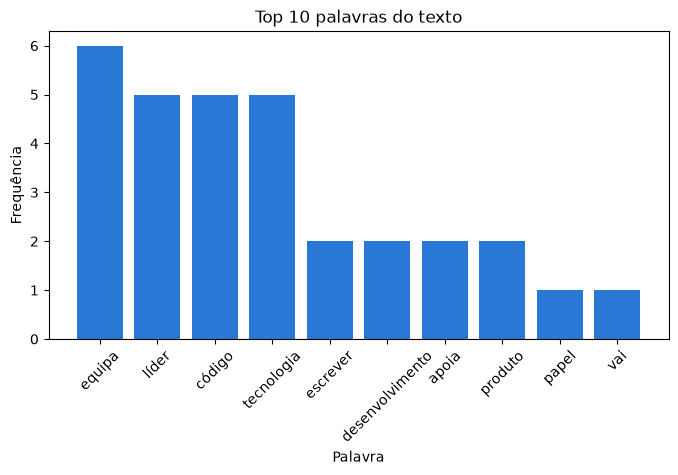

In [25]:
plt.figure(figsize=(8, 4))                             # 1. figura com 8 x 4 polegadas
plt.bar(top_palavras, top_contagens, color=AZUL)       # 2. desenhar barras (x = categorias, y = alturas)
plt.title("Top 10 palavras do texto")                  #    título e nomes dos eixos
plt.xlabel("Palavra")
plt.ylabel("Frequência")
plt.xticks(rotation=45)
plt.show()                                             # 3. mostrar

> 💡 **Dica:** escrever estes passos todos a cada gráfico cansa. Por isso, nas secções seguintes criamos **funções** que desenham um tipo de gráfico com um bom aspeto — e reutilizamo-las. Na secção 8 vamos mais longe e guardamos essas funções num **ficheiro próprio**.

<a id="sec-4-2"></a>

## 4.2. Gráfico de barras

Ideal para **comparar quantidades entre categorias**. Esta função desenha barras verticais ou horizontais, sem as "caixas" à volta (`spines`) que só fazem ruído:

In [26]:
def plot_barplot(abcissas, ordenadas, titulo="Palavras mais frequentes", horizontal=False):
    plt.figure(figsize=(10, 5))
    if horizontal:
        plt.barh(list(abcissas), list(ordenadas), color=AZUL)
        plt.gca().invert_yaxis()          # a maior barra fica em cima
        plt.xlabel("Frequência")
        plt.ylabel("Palavras")
    else:
        plt.bar(list(abcissas), list(ordenadas), color=AZUL)
        plt.xlabel("Palavras")
        plt.ylabel("Frequência")
        plt.xticks(rotation=90)
    plt.gca().spines[["top", "right"]].set_visible(False)   # tira as linhas de cima e da direita
    plt.title(titulo, fontsize=14, weight="bold", loc="left")
    plt.tight_layout()                    # ajusta as margens para nada ficar cortado
    plt.show()

**a) Todas as palavras (sem stop words)** — mesmo ordenadas, 50 e tal barras são difíceis de ler:

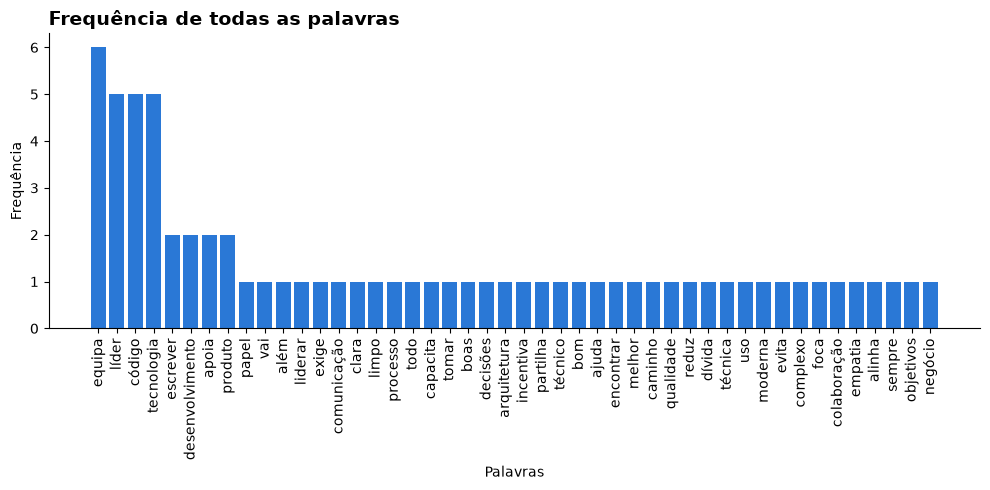

In [27]:
contagem_uteis = Counter(palavras_uteis)
todas = contagem_uteis.most_common()          # todas, da mais para a menos frequente
plot_barplot([p for p, n in todas], [n for p, n in todas], titulo="Frequência de todas as palavras")

**b) Top 10, na horizontal** — menos barras, ordenadas, rótulos legíveis:

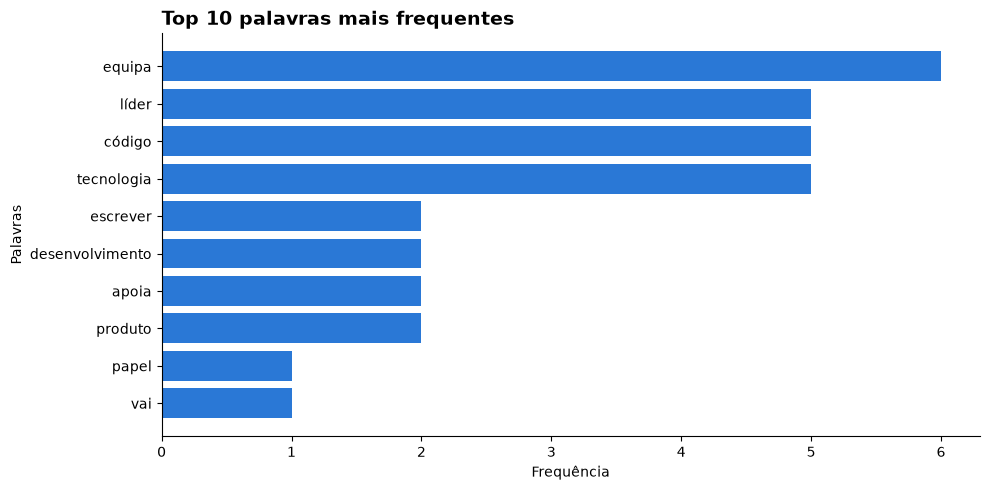

In [28]:
plot_barplot(top_palavras, top_contagens, titulo="Top 10 palavras mais frequentes", horizontal=True)

<a id="sec-4-3"></a>

## 4.3. Gráfico de linhas

Um gráfico de linhas mostra como um valor **varia ao longo de uma sequência** — normalmente o tempo, aqui a posição no texto. Vamos ver o número de caracteres de cada linha do ficheiro.

In [29]:
def plot_lineplot(abcissas, ordenadas, titulo="Evolução", xlabel="Eixo X", ylabel="Eixo Y"):
    plt.figure(figsize=(10, 5))
    plt.plot(list(abcissas), list(ordenadas), marker="o", color=AZUL, linewidth=2, markersize=7)
    plt.title(titulo, fontsize=14, weight="bold", loc="left")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(True, axis="y", color="#e1e0d9")              # grelha discreta, só na horizontal
    plt.gca().spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

In [30]:
caracteres_por_linha = {}
with open("data/text.txt", encoding="utf-8") as f:
    for numero, linha in enumerate(f, start=1):
        caracteres_por_linha[numero] = len(linha.strip())
        print(f"Linha {numero:2}: {caracteres_por_linha[numero]} caracteres")

Linha  1: 58 caracteres
Linha  2: 72 caracteres
Linha  3: 67 caracteres
Linha  4: 71 caracteres
Linha  5: 74 caracteres
Linha  6: 57 caracteres
Linha  7: 65 caracteres
Linha  8: 71 caracteres
Linha  9: 66 caracteres
Linha 10: 66 caracteres


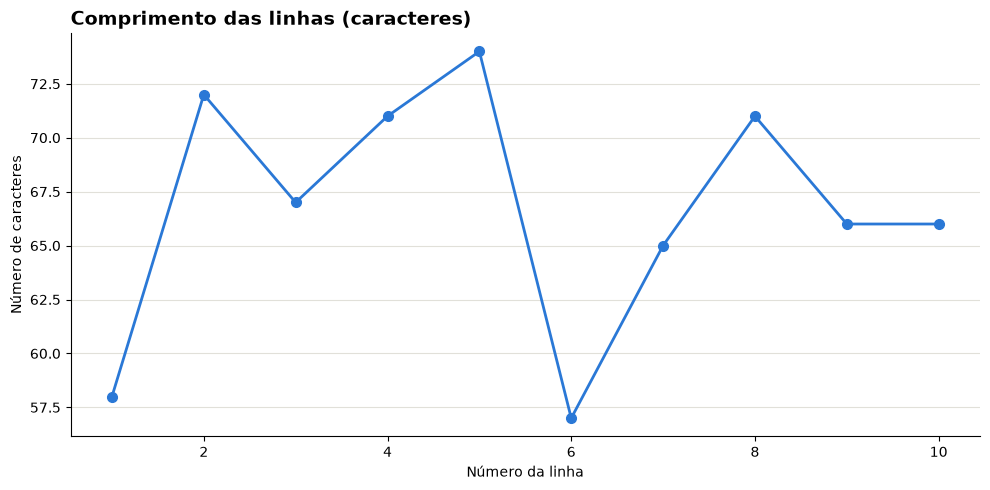

In [31]:
plot_lineplot(caracteres_por_linha.keys(), caracteres_por_linha.values(),
              titulo="Comprimento das linhas (caracteres)",
              xlabel="Número da linha", ylabel="Número de caracteres")

<a id="sec-4-4"></a>

## 4.4. Gráfico circular

O gráfico circular (*pie chart*) mostra a **proporção de cada categoria num todo**. Vamos usá-lo para ver que vogais aparecem mais no texto.

In [32]:
def plot_piechart(labels, valores, titulo="Distribuição de categorias"):
    plt.figure(figsize=(6, 6))
    plt.pie(list(valores), labels=list(labels), autopct="%1.1f%%", startangle=90,
            colors=CORES, wedgeprops={"edgecolor": "white", "linewidth": 2})   # fatias separadas por branco
    plt.title(titulo, fontsize=14, weight="bold")
    plt.axis("equal")          # garante que o círculo fica redondo
    plt.tight_layout()
    plt.show()

In [33]:
vogais = {"a": 0, "e": 0, "i": 0, "o": 0, "u": 0}
with open("data/text.txt", encoding="utf-8") as f:
    for linha in f:
        for letra in linha.lower():
            if letra in vogais:
                vogais[letra] += 1

for vogal, n in vogais.items():
    print(f"{vogal}: {n}")

a: 66
e: 64
i: 42
o: 65
u: 23


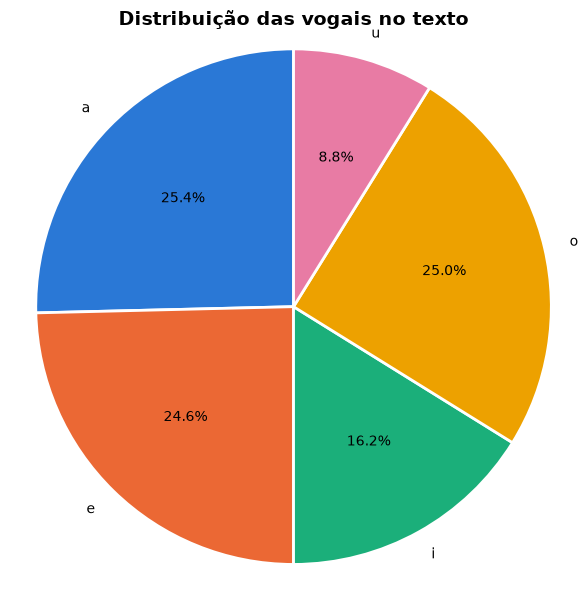

In [34]:
plot_piechart(vogais.keys(), vogais.values(), titulo="Distribuição das vogais no texto")

> ⚠️ **Cuidado:** este código só conta vogais sem acento — `á`, `é`, `ã`... ficam de fora. No desafio final vais corrigir isso. Além disso, os gráficos circulares só funcionam bem com **poucas** categorias (até 5 ou 6) e diferenças claras; para mais, usa barras.

<a id="sec-4-5"></a>

## 4.5. Gráfico de dispersão

O gráfico de dispersão (*scatter plot*) mostra a **relação entre duas variáveis numéricas**: cada ponto é uma observação. Pergunta: as linhas com mais caracteres também têm mais palavras?

In [35]:
def plot_scatter(x, y, titulo="Relação entre variáveis", xlabel="Variável X", ylabel="Variável Y"):
    plt.figure(figsize=(9, 5))
    plt.scatter(list(x), list(y), color=AZUL, edgecolors="white", linewidths=1.5, s=110)
    plt.yticks(range(min(y), max(y) + 1))                    # contagens: só números inteiros no eixo
    plt.title(titulo, fontsize=14, weight="bold", loc="left")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(True, color="#e1e0d9")
    plt.gca().spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

In [36]:
palavras_por_linha = []
caracteres = []
with open("data/text.txt", encoding="utf-8") as f:
    for linha in f:
        palavras_por_linha.append(len(linha.split()))
        caracteres.append(len(linha.strip()))

print("Palavras:  ", palavras_por_linha)
print("Caracteres:", caracteres)

Palavras:   [11, 11, 11, 12, 11, 11, 11, 13, 12, 11]
Caracteres: [58, 72, 67, 71, 74, 57, 65, 71, 66, 66]


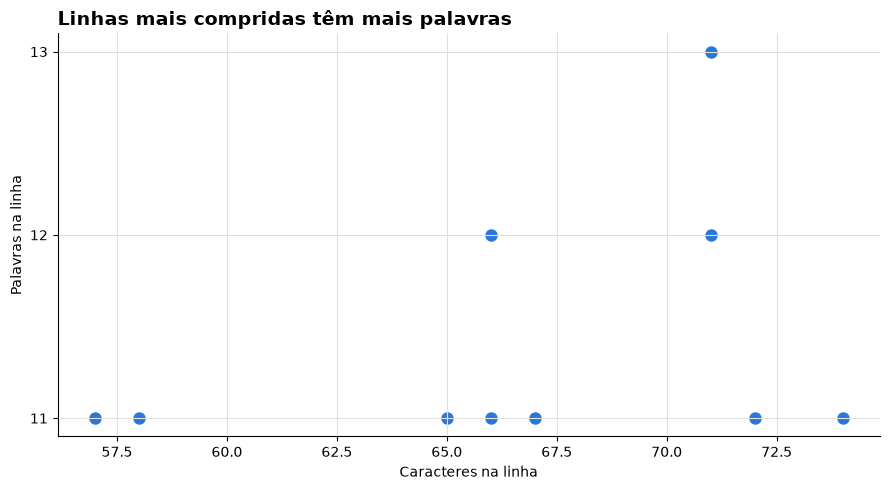

In [37]:
plot_scatter(caracteres, palavras_por_linha,
             titulo="Linhas mais compridas têm mais palavras",
             xlabel="Caracteres na linha", ylabel="Palavras na linha")

Os pontos sobem da esquerda para a direita: as duas variáveis estão **correlacionadas** (quando uma cresce, a outra tende a crescer). Na secção 6 vamos medir isto com um número.

### ✏️ Exercício 4 — Top 5 na vertical

**Dificuldade:** ⭐

Usa a função `plot_barplot` para desenhar as **5** palavras mais frequentes (sem stop words) em barras **verticais**, com o título `"Top 5 palavras"`.

*Dica:* `Counter(palavras_uteis).most_common(5)` e duas compreensões de lista.

In [38]:
# escreve aqui o teu código
top5 = []
print(top5)  # esperado: [('equipa', 6), ('líder', 5), ('código', 5), ('tecnologia', 5), ('escrever', 2)]

[]


<details>
<summary>💡 Ver solução</summary>

```python
top5 = Counter(palavras_uteis).most_common(5)
print(top5)
plot_barplot([p for p, n in top5], [n for p, n in top5], titulo="Top 5 palavras")
```

`most_common(5)` devolve uma lista de pares `(palavra, contagem)`; separamo-los em duas listas e passamo-las à função. Como `horizontal` vale `False` por omissão, as barras saem verticais.
</details>

> 📚 **Saber mais:** [W3Schools — Matplotlib Intro](https://www.w3schools.com/python/matplotlib_intro.asp) · [Pyplot](https://www.w3schools.com/python/matplotlib_pyplot.asp) · [Barras](https://www.w3schools.com/python/matplotlib_bars.asp) · [Linhas](https://www.w3schools.com/python/matplotlib_line.asp) · [Circular](https://www.w3schools.com/python/matplotlib_pie_charts.asp) · [Dispersão](https://www.w3schools.com/python/matplotlib_scatter.asp)

<a id="sec-5"></a>

# 5. Visualização com Seaborn

O **Seaborn** é construído por cima do Matplotlib. Faz gráficos estatísticos bonitos com menos código e — a sua grande força — trabalha diretamente com **DataFrames do pandas** (secção 6).

Vamos refazer os gráficos da secção 4 para comparar.

In [39]:
import seaborn as sns

<a id="sec-5-1"></a>

## 5.1. Estilos e temas

`sns.set_theme()` muda o aspeto de **todos** os gráficos seguintes (incluindo os do Matplotlib). Experimenta os vários estilos:

In [40]:
sns.set_theme(style="whitegrid")   # fundo branco com grelha cinzenta (bom para ler valores)

# Outras opções de estilo:
# sns.set_theme(style="darkgrid")   # fundo cinzento com grelha branca (o visual clássico do Seaborn)
# sns.set_theme(style="dark")       # fundo cinzento sem grelha
# sns.set_theme(style="white")      # fundo branco, sem grelha
# sns.set_theme(style="ticks")      # como "white", com pequenos traços nos eixos

<a id="sec-5-2"></a>

## 5.2. Gráfico de barras

`sns.barplot` com **uma cor de destaque**: a palavra mais frequente fica azul e as outras cinzentas — o olhar vai direto ao que interessa. Usamos `ax.bar_label` para escrever o valor no fim de cada barra (assim já nem precisamos do eixo dos números).

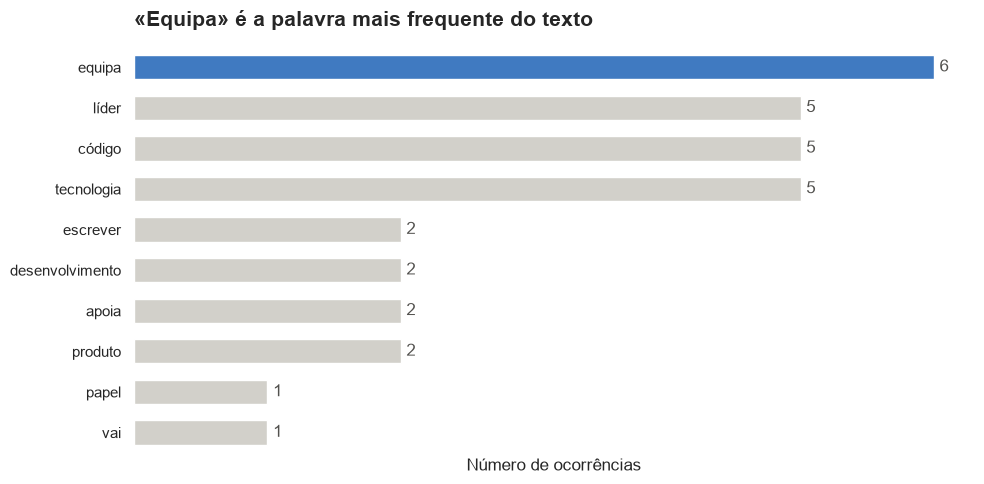

In [41]:
def plot_barplot_sns(x, y, titulo="Frequência de palavras"):
    sns.set_theme(style="white")
    plt.figure(figsize=(10, 5))

    # ordena do maior para o menor
    pares = sorted(zip(x, y), key=lambda par: par[1], reverse=True)
    palavras = [p for p, n in pares]
    frequencias = [n for p, n in pares]
    cores = [AZUL] + [CINZENTO] * (len(palavras) - 1)      # destaque só na primeira

    ax = sns.barplot(x=frequencias, y=palavras, hue=palavras, palette=cores, legend=False, width=0.6)
    for barras in ax.containers:          # um rótulo com o valor em cada barra
        ax.bar_label(barras, padding=4, color="#52514e")

    ax.set_title(titulo, fontsize=15, weight="bold", loc="left", pad=15)
    ax.set_xlabel("Número de ocorrências")
    ax.set_ylabel("")
    ax.set_xticks([])                     # os valores já estão escritos nas barras
    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.show()

plot_barplot_sns(top_palavras, top_contagens, titulo="«Equipa» é a palavra mais frequente do texto")

> 📝 **Nota:** no Seaborn, `hue` diz "pinta cada barra conforme esta variável". Aqui damos `hue=palavras` para podermos escolher a cor de cada barra com `palette`; `legend=False` esconde a legenda, que seria redundante. Repara que **não** usamos uma cor diferente por barra: um arco-íris não acrescenta informação e distrai.

<a id="sec-5-3"></a>

## 5.3. Gráfico de linhas

Em vez de escrever o valor em **todos** os pontos (fica uma confusão), escrevemos só o que interessa: o máximo.

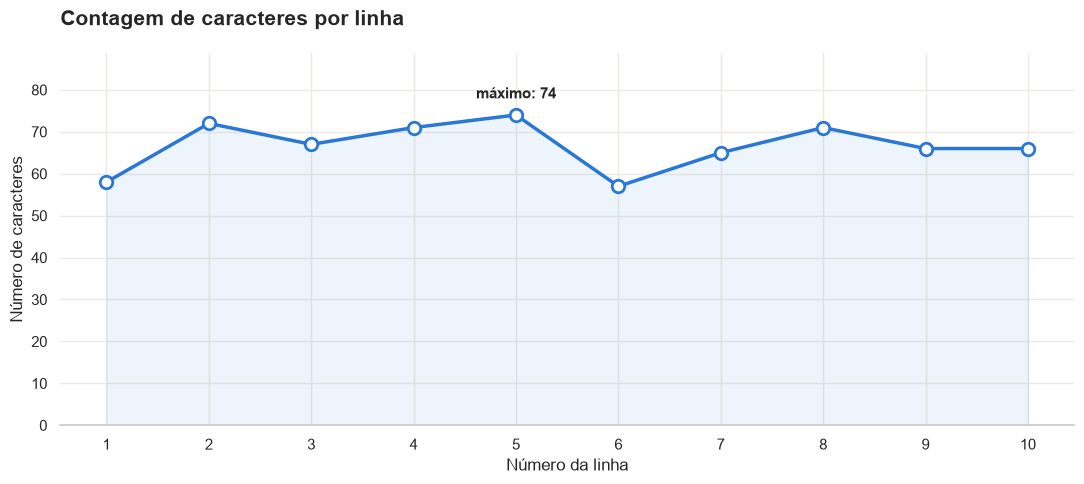

In [42]:
def plot_lineplot_sns(x, y, titulo="Número de caracteres por linha"):
    sns.set_theme(style="whitegrid", rc={"grid.color": "#eceae4"})
    x, y = list(x), list(y)
    plt.figure(figsize=(11, 5))

    ax = sns.lineplot(x=x, y=y, marker="o", markersize=9, linewidth=2.5, color=AZUL,
                      markerfacecolor="white", markeredgecolor=AZUL, markeredgewidth=2)
    plt.fill_between(x, y, color=AZUL, alpha=0.08)        # sombra suave por baixo da linha

    i_max = y.index(max(y))                                # só o máximo leva rótulo
    ax.annotate(f"máximo: {y[i_max]}", xy=(x[i_max], y[i_max]), xytext=(0, 12),
                textcoords="offset points", ha="center", fontsize=11, weight="bold")

    ax.set_title(titulo, fontsize=15, weight="bold", loc="left", pad=20)
    ax.set_xlabel("Número da linha")
    ax.set_ylabel("Número de caracteres")
    ax.set_xticks(x)
    ax.set_ylim(0, max(y) * 1.2)
    sns.despine(left=True)
    plt.tight_layout()
    plt.show()

plot_lineplot_sns(caracteres_por_linha.keys(), caracteres_por_linha.values(),
                  titulo="Contagem de caracteres por linha")

<a id="sec-5-4"></a>

## 5.4. Gráfico circular (donut)

O Seaborn **não tem** gráfico circular — continuamos a usar `plt.pie`, mas com um círculo branco no meio para o transformar num *donut*, e o total escrito no centro.

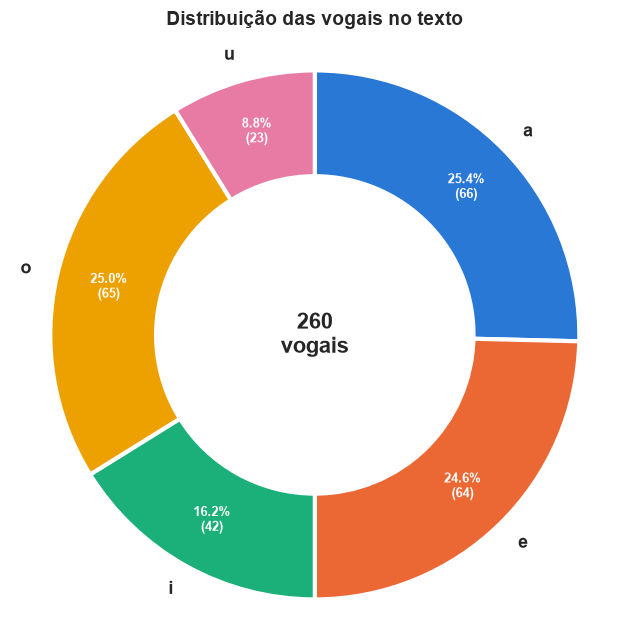

In [43]:
def plot_piechart_bonito(labels, valores, titulo="Distribuição de categorias"):
    labels, valores = list(labels), list(valores)
    total = sum(valores)

    def formatar(pct):                       # mostra a percentagem e o valor absoluto
        return f"{pct:.1f}%\n({round(pct * total / 100)})"

    plt.figure(figsize=(6.5, 6.5))
    fatias, textos, percentagens = plt.pie(
        valores, labels=labels, autopct=formatar, startangle=90, counterclock=False,
        colors=CORES[:len(labels)], pctdistance=0.80,
        textprops={"fontsize": 13, "weight": "bold"},
        wedgeprops={"linewidth": 3, "edgecolor": "white", "width": 0.4},   # width < 1 → buraco no meio
    )
    for p in percentagens:
        p.set_color("white")
        p.set_fontsize(9.5)

    plt.text(0, 0, f"{total}\nvogais", ha="center", va="center", fontsize=16, weight="bold")
    plt.title(titulo, fontsize=14, weight="bold", pad=15)
    plt.axis("equal")
    plt.tight_layout()
    plt.show()

plot_piechart_bonito(vogais.keys(), vogais.values(), titulo="Distribuição das vogais no texto")

<a id="sec-5-5"></a>

## 5.5. Gráfico de dispersão

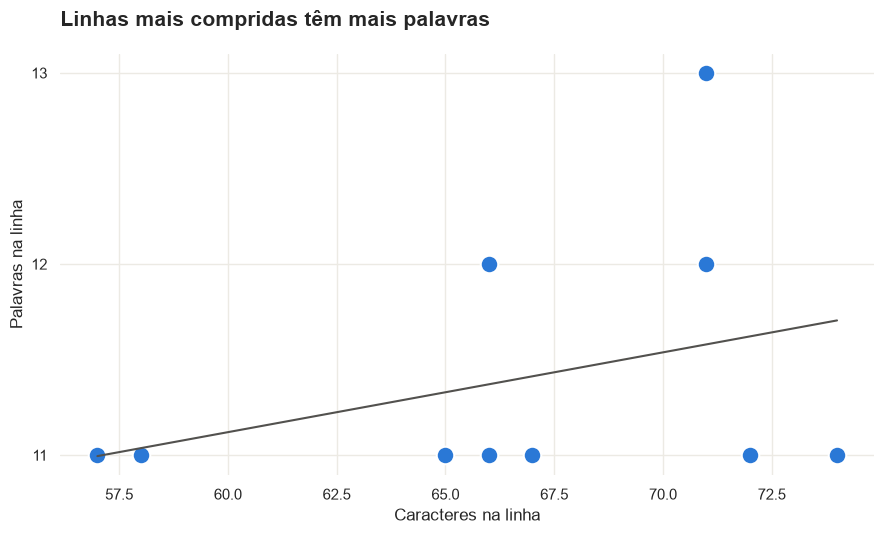

In [44]:
def plot_scatter_sns(x, y, titulo="Relação entre variáveis", xlabel="Variável X", ylabel="Variável Y"):
    sns.set_theme(style="whitegrid", rc={"grid.color": "#eceae4"})
    plt.figure(figsize=(9, 5.5))
    ax = sns.scatterplot(x=list(x), y=list(y), color=AZUL, s=160, edgecolor="white", linewidth=1.5)
    sns.regplot(x=list(x), y=list(y), scatter=False, ci=None, color="#52514e",
                line_kws={"linewidth": 1.5})                  # reta de tendência
    ax.set_title(titulo, fontsize=15, weight="bold", loc="left", pad=20)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_yticks(range(min(y), max(y) + 1))                 # contagens: só números inteiros
    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.show()

plot_scatter_sns(caracteres, palavras_por_linha,
                 titulo="Linhas mais compridas têm mais palavras",
                 xlabel="Caracteres na linha", ylabel="Palavras na linha")

> 💡 **Dica:** `sns.regplot` desenha a **reta de tendência** — a linha reta que melhor acompanha os pontos. Com `scatter=False` desenha só a reta, por cima dos nossos pontos.

<a id="sec-5-6"></a>

## 5.6. Nuvem de palavras (WordCloud)

Uma **nuvem de palavras** desenha cada palavra com um tamanho proporcional à sua frequência. Não é um gráfico rigoroso (é difícil comparar tamanhos de letra), mas dá uma **primeira impressão** rápida dos temas de um texto.

A biblioteca `wordcloud` recebe o texto e trata de tudo; com o parâmetro `stopwords` passamos a nossa lista de palavras a ignorar.

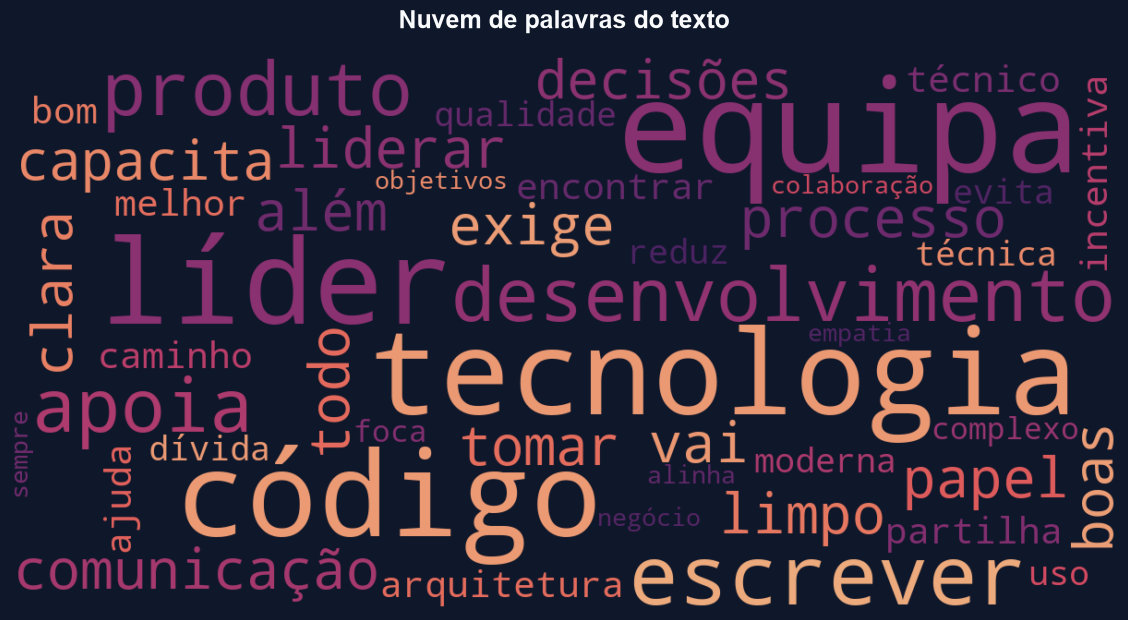

In [45]:
from wordcloud import WordCloud

texto_limpo = " ".join(palavras)          # texto já normalizado (secção 3.2)

nuvem = WordCloud(
    width=1200, height=600,
    background_color="#0f172a",           # fundo azul-escuro
    colormap="flare",                     # paleta do Seaborn
    stopwords=STOP_WORDS,                 # ignora as stop words
    collocations=False,                   # conta palavras soltas, não pares de palavras
    max_font_size=140, min_font_size=12,
    prefer_horizontal=0.85,
    random_state=42,                      # mesma disposição sempre que executas
    margin=4,
).generate(texto_limpo)

plt.figure(figsize=(12, 6), facecolor="#0f172a")
plt.imshow(nuvem, interpolation="bilinear")
plt.axis("off")
plt.title("Nuvem de palavras do texto", fontsize=18, weight="bold", color="#f8fafc", pad=20)
plt.tight_layout(pad=0)
plt.show()

> 💡 **Dica:** experimenta tirar `stopwords=STOP_WORDS` e volta a executar — as palavras gramaticais (`de`, `a`, `e`) passam a ocupar o centro da nuvem.

> 📚 **Saber mais:** [Seaborn — tutorial oficial](https://seaborn.pydata.org/tutorial.html) · [Seaborn — galeria de exemplos](https://seaborn.pydata.org/examples/index.html)

<a id="sec-6"></a>

# 6. Seaborn com DataFrames

Até aqui demos ao Seaborn **listas** soltas. Mas o Seaborn foi pensado para **tabelas**: passas-lhe um DataFrame em `data=` e dizes, pelo **nome das colunas**, o que vai para cada eixo:

```python
sns.scatterplot(data=df, x="coluna_a", y="coluna_b", hue="coluna_c")
```

É aqui que tudo o que aprendeste com o pandas no notebook 05 compensa.

In [46]:
import pandas as pd

sns.set_theme(style="whitegrid", rc={"grid.color": "#eceae4", "axes.edgecolor": "#c3c2b7"})

<a id="sec-6-1"></a>

## 6.1. Da lista ao DataFrame

Começamos por pôr as medidas de cada linha do `text.txt` numa tabela:

In [47]:
df_linhas = pd.DataFrame({
    "linha": list(caracteres_por_linha.keys()),
    "caracteres": caracteres,
    "palavras": palavras_por_linha,
})
df_linhas["comprimento_medio"] = (df_linhas["caracteres"] / df_linhas["palavras"]).round(2)
df_linhas.head()

,linha,caracteres,palavras,comprimento_medio
0,1,58,11,5.27
1,2,72,11,6.55
2,3,67,11,6.09
3,4,71,12,5.92
4,5,74,11,6.73


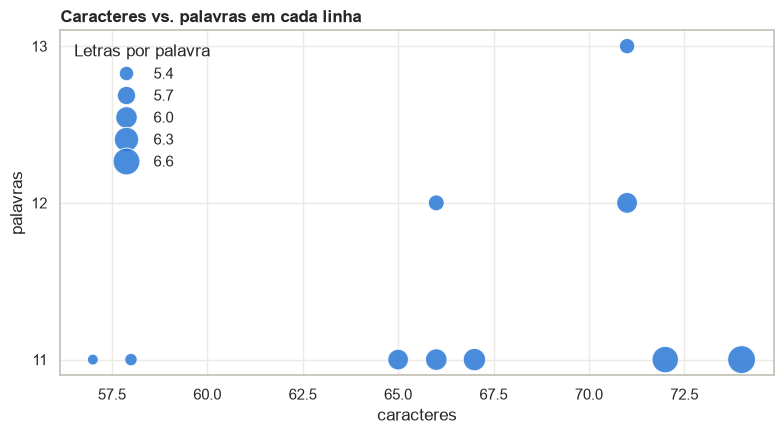

In [48]:
plt.figure(figsize=(8, 4.5))
sns.scatterplot(data=df_linhas, x="caracteres", y="palavras", size="comprimento_medio",
                sizes=(60, 400), color=AZUL, edgecolor="white", alpha=0.85)
plt.title("Caracteres vs. palavras em cada linha", weight="bold", loc="left")
plt.yticks([11, 12, 13])
plt.legend(title="Letras por palavra", frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

Repara que já não precisamos de `xlabel`/`ylabel`: o Seaborn usa os nomes das colunas. E `size=` acrescentou uma terceira variável (o tamanho dos pontos) com uma só palavra.

<a id="sec-6-2"></a>

## 6.2. Os pinguins de Palmer

Dez linhas são poucas para gráficos estatísticos. Vamos usar um dataset clássico para aprender visualização: **344 pinguins** de três espécies (Adelie, Chinstrap e Gentoo), medidos por cientistas em três ilhas da Antártida.

| Coluna original | Em português | Significado |
|---|---|---|
| `species` | `especie` | Adelie, Chinstrap ou Gentoo |
| `island` | `ilha` | Biscoe, Dream ou Torgersen |
| `bill_length_mm` / `bill_depth_mm` | `bico_comprimento_mm` / `bico_profundidade_mm` | tamanho do bico (mm) |
| `flipper_length_mm` | `barbatana_mm` | comprimento da barbatana (mm) |
| `body_mass_g` | `massa_g` | massa corporal (gramas) |
| `sex` | `sexo` | macho ou fêmea |

In [49]:
pinguins = pd.read_csv("data/penguins.csv")

pinguins = pinguins.rename(columns={
    "species": "especie", "island": "ilha",
    "bill_length_mm": "bico_comprimento_mm", "bill_depth_mm": "bico_profundidade_mm",
    "flipper_length_mm": "barbatana_mm", "body_mass_g": "massa_g", "sex": "sexo",
})
pinguins["sexo"] = pinguins["sexo"].map({"MALE": "macho", "FEMALE": "fêmea"})

print(pinguins.shape)
pinguins.head()

(344, 7)


,especie,ilha,bico_comprimento_mm,bico_profundidade_mm,barbatana_mm,massa_g,sexo
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,macho
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,fêmea
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,fêmea
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,fêmea


In [50]:
pinguins["especie"].value_counts()

especie
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Cada espécie vai ter **sempre a mesma cor** em todos os gráficos — assim, quem olha aprende uma vez que "Gentoo é verde" e não tem de reaprender a cada gráfico:

In [51]:
CORES_ESPECIES = {"Adelie": "#2a78d6", "Chinstrap": "#eb6834", "Gentoo": "#1baf7a"}

> 📝 **Nota:** os dados são do projeto *Palmer Penguins* (Dra. Kristen Gorman, Palmer Station, Antártida), livres para usar. Há alguns valores em falta (`NaN`) — o Seaborn ignora-os sozinho.

<a id="sec-6-3"></a>

## 6.3. Histograma: `histplot`

Um histograma mostra a **distribuição** de uma variável numérica: em que valores se concentram os dados? Cada barra conta quantos pinguins têm a barbatana nesse intervalo.

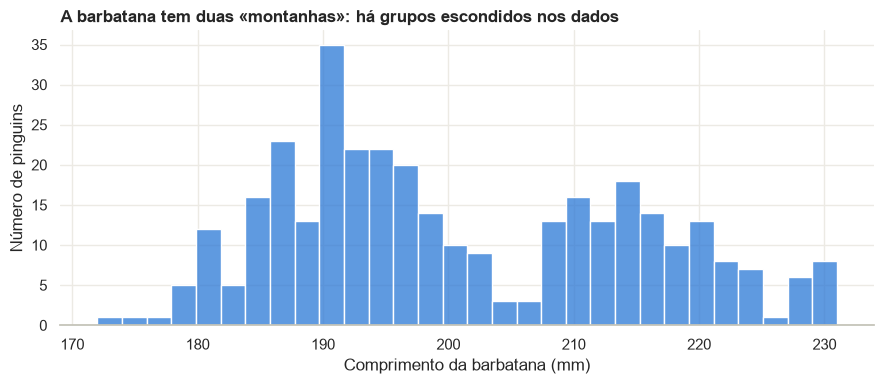

In [52]:
plt.figure(figsize=(9, 4))
sns.histplot(data=pinguins, x="barbatana_mm", bins=30, color=AZUL, edgecolor="white")
plt.title("A barbatana tem duas «montanhas»: há grupos escondidos nos dados", weight="bold", loc="left")
plt.xlabel("Comprimento da barbatana (mm)")
plt.ylabel("Número de pinguins")
sns.despine(left=True)
plt.tight_layout()
plt.show()

Duas "montanhas" (uma perto de 190 mm e outra perto de 215 mm) são um sinal de que os dados misturam **grupos diferentes**. Quais? O próximo gráfico responde.

<a id="sec-6-4"></a>

## 6.4. Caixa de bigodes: `boxplot`

O *boxplot* resume uma distribuição em 5 números: a **caixa** vai do 1.º ao 3.º quartil (onde estão 50% dos dados), o traço dentro é a **mediana**, os **bigodes** mostram o alcance normal e os pontos soltos são **outliers** (valores atípicos). É ótimo para **comparar grupos**.

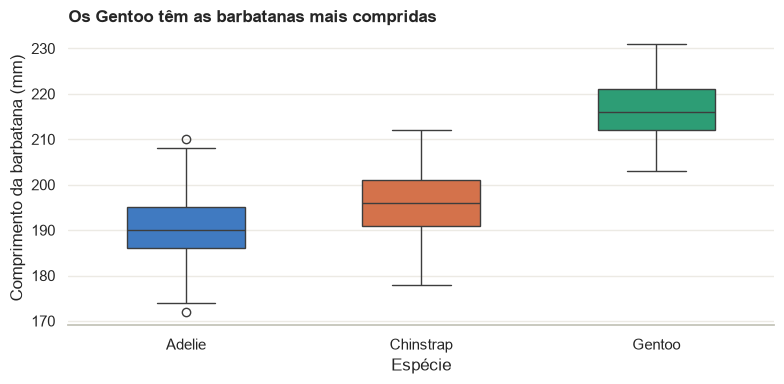

In [53]:
ordem = pinguins.groupby("especie")["barbatana_mm"].median().sort_values().index   # da menor para a maior

plt.figure(figsize=(8, 4))
sns.boxplot(data=pinguins, x="especie", y="barbatana_mm", order=ordem,
            hue="especie", palette=CORES_ESPECIES, legend=False, width=0.5)
plt.title("Os Gentoo têm as barbatanas mais compridas", weight="bold", loc="left")
plt.xlabel("Espécie")
plt.ylabel("Comprimento da barbatana (mm)")
sns.despine(left=True)
plt.tight_layout()
plt.show()

Mistério resolvido: a "montanha" da direita do histograma são os **Gentoo**. As caixas estão ordenadas pela mediana — fica logo claro quem é o maior.

<a id="sec-6-5"></a>

## 6.5. Dispersão com cor: `scatterplot` + `hue`

Com `hue=` pintamos os pontos conforme uma terceira coluna. Hipótese: pinguins com barbatanas maiores também pesam mais?

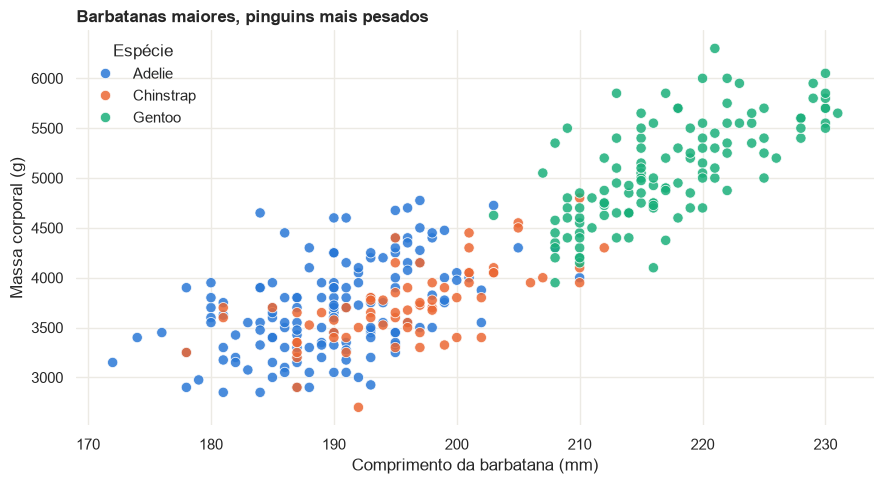

In [54]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=pinguins, x="barbatana_mm", y="massa_g", hue="especie",
                palette=CORES_ESPECIES, s=55, edgecolor="white", alpha=0.85)
plt.title("Barbatanas maiores, pinguins mais pesados", weight="bold", loc="left")
plt.xlabel("Comprimento da barbatana (mm)")
plt.ylabel("Massa corporal (g)")
plt.legend(title="Espécie", frameon=False)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

<a id="sec-6-6"></a>

## 6.6. O Titanic e o `barplot`

O segundo dataset é a lista de **891 passageiros do Titanic** (1912): classe, sexo, idade, preço do bilhete... e se sobreviveram (`1`) ou não (`0`). Ficamos com as colunas que interessam, em português:

In [55]:
titanic = pd.read_csv("data/titanic.csv")

titanic = titanic.rename(columns={
    "survived": "sobreviveu", "pclass": "classe", "sex": "sexo",
    "age": "idade", "fare": "tarifa", "embark_town": "porto",
})[["sobreviveu", "classe", "sexo", "idade", "tarifa", "porto"]]

titanic["classe"] = titanic["classe"].map({1: "1.ª classe", 2: "2.ª classe", 3: "3.ª classe"})
titanic["sexo"] = titanic["sexo"].map({"male": "homem", "female": "mulher"})

print(titanic.shape)
titanic.head()

(891, 6)


,sobreviveu,classe,sexo,idade,tarifa,porto
0,0,3.ª classe,homem,22.0,7.2500,Southampton
1,1,1.ª classe,mulher,38.0,71.2833,Cherbourg
2,1,3.ª classe,mulher,26.0,7.9250,Southampton
3,1,1.ª classe,mulher,35.0,53.1000,Southampton
4,0,3.ª classe,homem,35.0,8.0500,Southampton


Um truque útil: como `sobreviveu` só tem `0` e `1`, a sua **média** é a **proporção de sobreviventes**. E quando o `sns.barplot` recebe várias linhas por categoria, desenha precisamente a média de cada grupo:

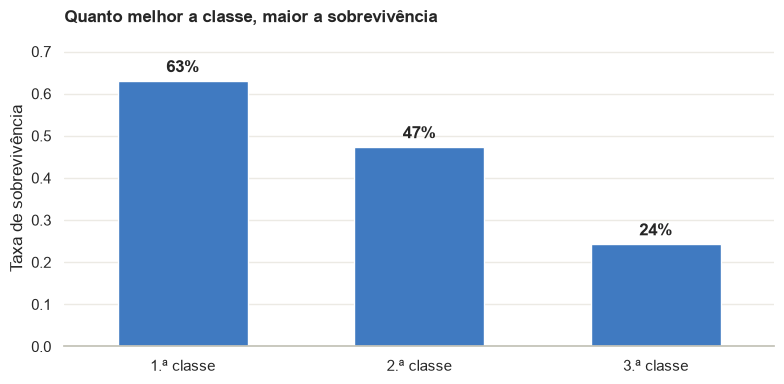

In [56]:
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=titanic, x="classe", y="sobreviveu", order=["1.ª classe", "2.ª classe", "3.ª classe"],
                 color=AZUL, errorbar=None, width=0.55)
ax.bar_label(ax.containers[0], fmt="{:.0%}", padding=4, weight="bold")   # 0.63 → 63%
plt.title("Quanto melhor a classe, maior a sobrevivência", weight="bold", loc="left")
plt.xlabel("")
plt.ylabel("Taxa de sobrevivência")
plt.ylim(0, 0.75)
sns.despine(left=True)
plt.tight_layout()
plt.show()

> 💡 **Dica:** acrescenta `hue="sexo"` ao `sns.barplot` e vês as barras de homens e mulheres lado a lado em cada classe. A diferença é enorme — vamos vê-la com mais detalhe na secção 8.

> 📝 **Nota:** aqui as classes ficam pela sua **ordem natural** (1.ª, 2.ª, 3.ª), que já coincide com a ordem dos valores.

<a id="sec-6-7"></a>

## 6.7. Mapa de calor de correlações: `heatmap`

A **correlação** mede, entre −1 e +1, quanto duas colunas numéricas variam juntas:

- perto de **+1** → quando uma sobe, a outra sobe;
- perto de **−1** → quando uma sobe, a outra desce;
- perto de **0** → não há relação (linear).

O pandas calcula todas as correlações com `.corr()` e o `heatmap` pinta a tabela.

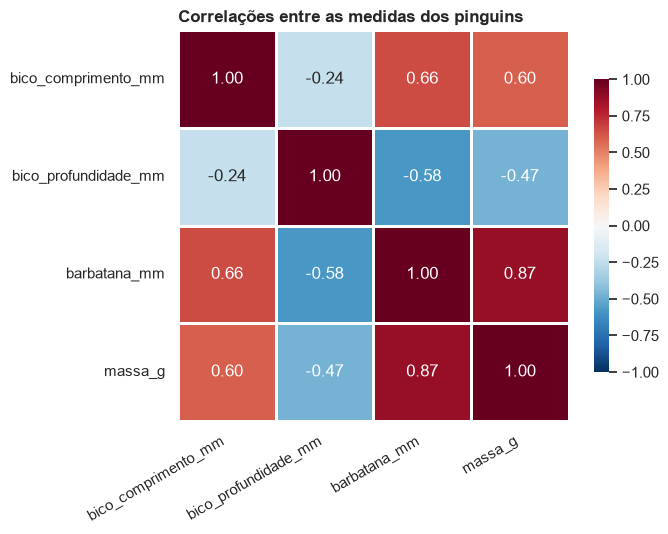

In [57]:
medidas = pinguins[["bico_comprimento_mm", "bico_profundidade_mm", "barbatana_mm", "massa_g"]]
correlacoes = medidas.corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(correlacoes, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=2, linecolor="white", cbar_kws={"shrink": 0.75})
plt.title("Correlações entre as medidas dos pinguins", weight="bold", loc="left")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Lê-se assim: `barbatana_mm` e `massa_g` estão fortemente correlacionadas (**0,87**) — o que vimos no gráfico de dispersão. Usamos uma paleta **divergente** (azul ↔ vermelho, com branco no zero), porque o sinal importa: azul = negativa, vermelho = positiva.

Curioso: o comprimento e a profundidade do bico têm correlação **negativa** (−0,24)... Guarda esta ideia — na secção 8 vais descobrir que este número engana!

> 🤖 **Ligação à IA:** antes de treinar um modelo, olhar para as correlações ajuda a perceber que colunas podem ser úteis para prever outra — e quais são redundantes.

> ⚠️ **Cuidado:** correlação não é causalidade. Duas colunas podem variar juntas sem que uma cause a outra.

### ✏️ Exercício 5 — Titanic: sobrevivência por porto de embarque

**Dificuldade:** ⭐⭐

O Titanic parou em três portos: Southampton, Cherbourg e Queenstown. Calcula a **taxa de sobrevivência** de cada porto (média de `sobreviveu`), **ordena** do maior para o menor e desenha um gráfico de barras **horizontal** com título e eixos.

*Dicas:* `titanic.groupby("porto")["sobreviveu"].mean()`, depois `.sort_values(ascending=False)`; no `sns.barplot` passa `x=taxa_porto.values` e `y=taxa_porto.index`.

```text
porto
Cherbourg      0.554
Queenstown     0.390
Southampton    0.337
```

In [58]:
# escreve aqui o teu código
taxa_porto = pd.Series(dtype=float)
print(taxa_porto.round(3))  # esperado: Cherbourg 0.554, Queenstown 0.39, Southampton 0.337

Series([], dtype: float64)


<details>
<summary>💡 Ver solução</summary>

```python
taxa_porto = titanic.groupby("porto")["sobreviveu"].mean().sort_values(ascending=False)
print(taxa_porto.round(3))

plt.figure(figsize=(8, 3))
ax = sns.barplot(x=taxa_porto.values, y=taxa_porto.index, color=AZUL, width=0.55)
ax.bar_label(ax.containers[0], fmt="{:.0%}", padding=4)
plt.title("Quem embarcou em Cherbourg sobreviveu mais", weight="bold", loc="left")
plt.xlabel("Taxa de sobrevivência")
plt.ylabel("")
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()
```

`groupby` + `mean()` dá a proporção de sobreviventes de cada porto; `sort_values(ascending=False)` ordena. No `barplot` horizontal, a primeira categoria fica em cima. (Porquê Cherbourg? Lá embarcaram muitos passageiros de 1.ª classe — lembra-te do gráfico da secção 6.6.)
</details>

> 📚 **Saber mais:** [W3Schools — Histogramas](https://www.w3schools.com/python/matplotlib_histograms.asp) · [Seaborn — galeria de exemplos](https://seaborn.pydata.org/examples/index.html)

<a id="sec-7"></a>

# 7. Boas práticas de gráficos

Um gráfico serve para **comunicar**. Antes de o partilhar, confirma:

1. **Título que diz a conclusão** — "Barbatanas maiores, pinguins mais pesados" diz mais do que "Gráfico de dispersão".
2. **Eixos com nome e unidades** — `plt.xlabel`, `plt.ylabel`.
3. **Barras ordenadas** — do maior para o menor, salvo se a ordem natural importar (meses, anos, classes).
4. **Uma mensagem por gráfico** — se queres dizer duas coisas, faz dois gráficos.
5. **Cor com propósito** — usa cor para destacar ou para identificar um grupo (sempre a mesma cor para o mesmo grupo), não para enfeitar. Evita arco-íris.
6. **O tipo certo** — barras para comparar, linhas para evoluções, dispersão para relações, histograma/boxplot para distribuições, circular só com poucas categorias.
7. **Menos tinta, mais dados** — tira caixas, grelhas pesadas e legendas repetidas; escreve os valores só onde ajudam.
8. **`plt.tight_layout()`** para nada ficar cortado, e **`plt.savefig()`** para guardar o gráfico num ficheiro.

Compara o mesmo gráfico, antes e depois:

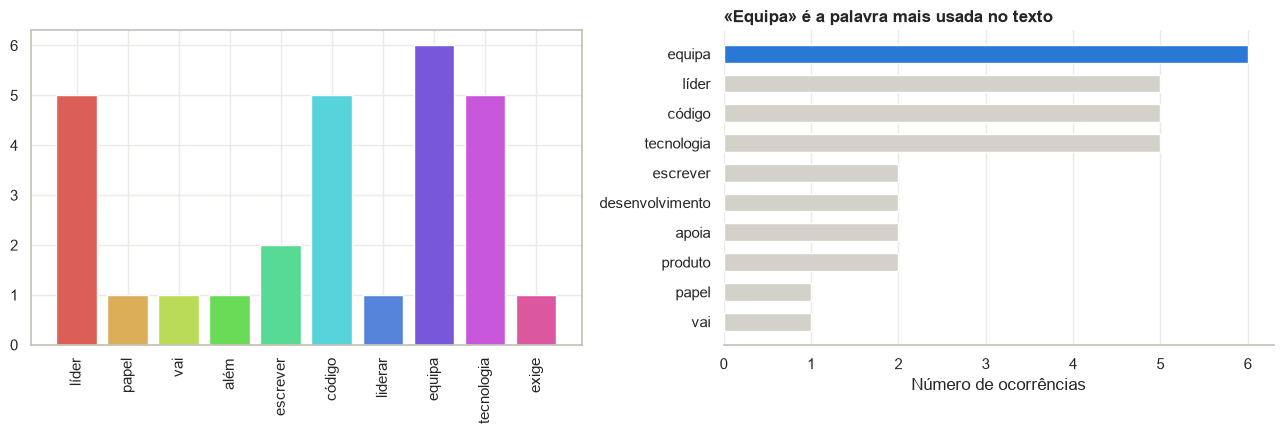

Gráfico guardado em output/antes_depois.png


In [59]:
fig, (antes, depois) = plt.subplots(1, 2, figsize=(13, 4.5))   # dois gráficos lado a lado

# ❌ Antes: palavras pela ordem do texto, cores aleatórias, sem títulos nem eixos
primeiras = list(contagem_uteis.items())[:10]
antes.bar([p for p, n in primeiras], [n for p, n in primeiras], color=sns.color_palette("hls", 10))
antes.tick_params(axis="x", rotation=90)

# ✅ Depois: ordenado, uma cor, destaque na palavra principal, título com mensagem
cores = [AZUL] + [CINZENTO] * 9
depois.barh(top_palavras[::-1], top_contagens[::-1], color=cores[::-1], height=0.6)
depois.set_title("«Equipa» é a palavra mais usada no texto", weight="bold", loc="left")
depois.set_xlabel("Número de ocorrências")
depois.grid(False, axis="y")
depois.spines[["top", "right", "left"]].set_visible(False)

plt.tight_layout()
plt.savefig("output/antes_depois.png", dpi=150)   # guarda a figura em output/
plt.show()
print("Gráfico guardado em output/antes_depois.png")

> 💡 **Dica:** `plt.savefig()` tem de vir **antes** de `plt.show()` — depois de mostrada, a figura é limpa e gravarias uma imagem em branco. Usa `dpi=150` (ou mais) para uma imagem nítida.

Seguir estas 8 regras à mão em cada gráfico dá trabalho... Na próxima secção vais pô-las todas **dentro de funções**, num ficheiro só teu.

> 📚 **Saber mais:** [W3Schools — Títulos e eixos](https://www.w3schools.com/python/matplotlib_labels.asp) · [W3Schools — Subplots](https://www.w3schools.com/python/matplotlib_subplot.asp)

<a id="sec-8"></a>

# 8. ✨ Gráficos profissionais com o teu próprio módulo

Na secção 7 viste o que faz um gráfico bonito e claro. Fazer tudo isso à mão, gráfico a gráfico, dá muito trabalho — e é fácil esquecer um passo.

A solução de quem programa: **escrever o código uma vez, guardá-lo num ficheiro `.py` e importá-lo** sempre que for preciso. Ao lado deste notebook está o ficheiro **`graficos.py`**, um pequeno módulo com funções que fazem gráficos com aspeto profissional numa só linha:

| Função | Gráfico | Usa para... |
|---|---|---|
| `barras(dados, titulo, destaque=...)` | barras horizontais ordenadas, com valores | comparar categorias |
| `linha(dados, titulo, ...)` | linha com área suave | evolução numa sequência |
| `histograma(df, coluna, titulo, cor_por=...)` | histograma (um ou vários grupos) | distribuição |
| `dispersao(df, x, y, cor=...)` | pontos coloridos por grupo | relação entre 2 números |
| `caixa(df, coluna, por=..., tipo=...)` | violino ou caixa de bigodes | comparar distribuições |
| `donut(dados, titulo)` | circular com buraco | partes de um todo (poucas) |
| `mapa_calor(df, titulo)` | correlações | ver que colunas andam juntas |
| `nuvem_palavras(dados, titulo)` | nuvem de palavras | primeira impressão de um texto |
| `guardar(fig, nome)` | — | gravar o gráfico em `output/` |

<a id="sec-8-1"></a>

## 8.1. Importar funções de um ficheiro `.py`

Já fizeste isto no [notebook 04 — Módulos e imports](../04_Modules_Errors_Classes/04_Modules_Errors_Classes.ipynb): um ficheiro `.py` na mesma pasta é um **módulo**, e importamos o que precisamos com `from módulo import nome`. O nome do módulo é o nome do ficheiro, sem `.py`:

In [60]:
from graficos import aplicar_tema, barras, linha, histograma, dispersao, caixa
from graficos import donut, mapa_calor, nuvem_palavras, guardar, PALETA

aplicar_tema()      # aplica o estilo a todos os gráficos seguintes
print(PALETA)       # as cores do módulo, por ordem

['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']


`aplicar_tema()` muda o tipo de letra (Inter), as cores, a grelha e as margens de **todos** os gráficos seguintes — até dos que fizeres à mão com `plt` ou `sns`.

Agora, o Top 10 de palavras da secção 4 — numa só linha:

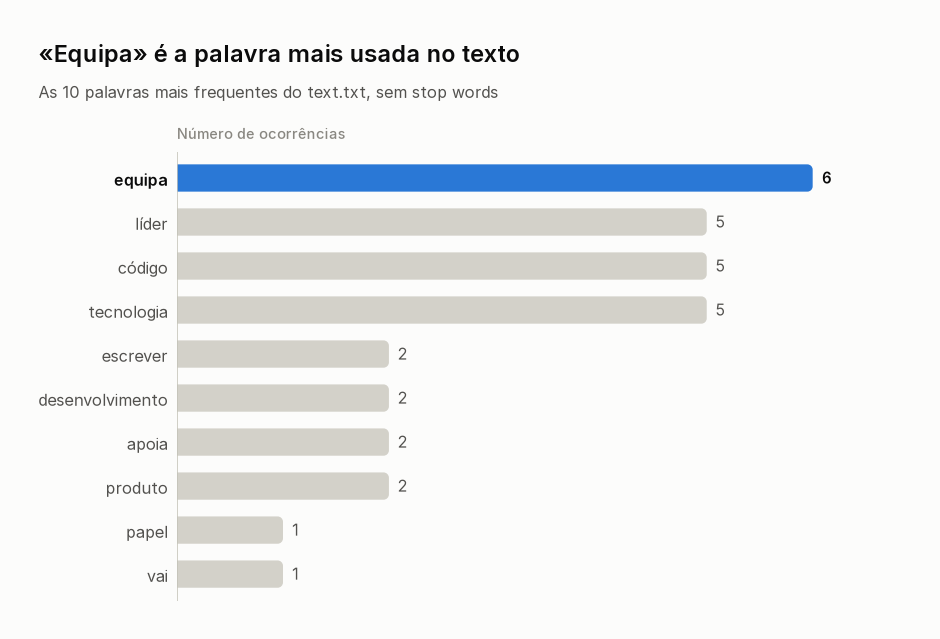

In [61]:
fig, ax = barras(top10, titulo="«Equipa» é a palavra mais usada no texto",
                 subtitulo="As 10 palavras mais frequentes do text.txt, sem stop words",
                 destaque="equipa", rotulo_valor="Número de ocorrências")

Repara em tudo o que a função fez sozinha: ordenou as barras, escreveu os valores, destacou uma barra, arredondou as pontas, alinhou o título e o subtítulo, limpou os eixos. Isto é o poder de **reutilizar código**.

> 💡 **Dica:** todas as funções devolvem `(fig, ax)` — a figura e os eixos do Matplotlib. Escreve sempre `fig, ax = ...` (assim não aparece texto extra por baixo do gráfico) e, se quiseres, afina com os comandos que já conheces, por exemplo `ax.set_xlim(0, 10)`.

> ⚠️ **Cuidado:** o Python só lê um módulo **uma vez** por sessão. Se alterares o `graficos.py`, reinicia o kernel (**Kernel → Restart**) ou recarrega o módulo:
>
> ```python
> import importlib
> import graficos
> importlib.reload(graficos)          # volta a ler o ficheiro
> from graficos import barras         # e volta a importar o que precisas
> ```

<a id="sec-8-2"></a>

## 8.2. Conhecer as funções com `help()`

Como sabes que parâmetros tem uma função? Cada função do módulo tem uma **docstring** — o texto entre aspas triplas logo a seguir ao `def` — que explica o que faz. O `help()` mostra-a:

In [62]:
help(barras)

Help on function barras in module graficos:

barras(dados: 'Any', titulo: 'str', subtitulo: 'str | None' = None, destaque: 'str | Sequence[str] | None' = None, rotulo_valor: 'str | None' = None, formato: 'str | None' = None, maximo: 'int | None' = None, ordenar: 'bool' = True, fonte: 'str | None' = None, largura: 'float' = 8.5)
    Barras horizontais, ordenadas, com o valor escrito na ponta de cada barra.

    Args:
        dados: um ``dict`` (``{"a": 3, "b": 5}``), um ``Counter``, uma pandas
            ``Series`` (o índice dá os nomes) ou uma lista de pares
            ``[("a", 3), ("b", 5)]``.
        titulo: a mensagem do gráfico, de preferência a conclusão.
        subtitulo: o que se mede e em que unidades.
        destaque: o nome (ou lista de nomes) da barra a destacar. As outras
            ficam cinzentas — assim o olhar vai direto ao que interessa.
        rotulo_valor: o nome do eixo dos valores (aparece por baixo).
        formato: como escrever os valores, por exemplo ``"

> 💡 **Dica:** no Jupyter também podes escrever `barras?` numa célula, ou carregar em `Shift`+`Tab` com o cursor dentro dos parênteses. E podes abrir o `graficos.py` no VS Code para ler o código — está todo comentado.

<a id="sec-8-3"></a>

## 8.3. Galeria: os pinguins

**Lembras-te da correlação negativa entre o comprimento e a profundidade do bico (−0,24)?** Vamos olhar para os pontos, separados por espécie, com uma reta de tendência por grupo (`tendencia=True`):

Gráfico guardado em output/pinguins_bico.png


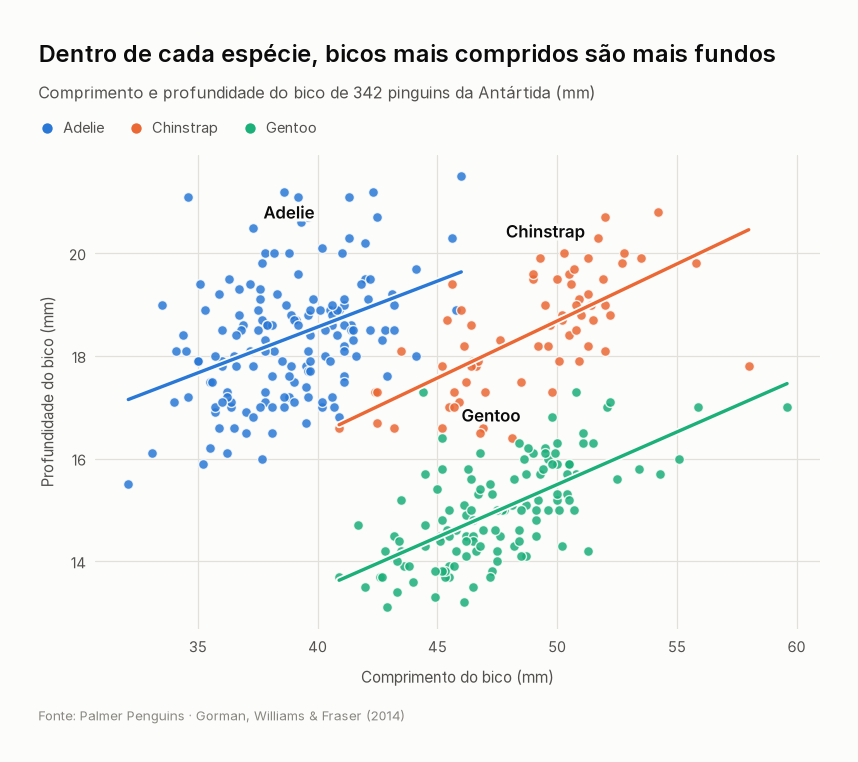

In [63]:
fig, ax = dispersao(
    pinguins, x="bico_comprimento_mm", y="bico_profundidade_mm", cor="especie", tendencia=True,
    titulo="Dentro de cada espécie, bicos mais compridos são mais fundos",
    subtitulo="Comprimento e profundidade do bico de 342 pinguins da Antártida (mm)",
    rotulo_x="Comprimento do bico (mm)", rotulo_y="Profundidade do bico (mm)",
    fonte="Palmer Penguins · Gorman, Williams & Fraser (2014)",
)
guardar(fig, "pinguins_bico")

Surpresa: **dentro de cada espécie**, as retas sobem (correlação positiva)! A correlação negativa aparecia só porque misturávamos espécies — os Gentoo têm bicos compridos mas pouco fundos e puxam tudo para baixo. Chama-se **paradoxo de Simpson**, e é a melhor prova de que vale a pena **olhar para os dados** e não só para um número.

> 🤖 **Ligação à IA:** um modelo treinado sem a coluna `especie` aprenderia a relação errada. Escolher bem as colunas (e visualizá-las antes) faz parte de treinar bons modelos.

Quanto pesa cada espécie? Um **violino** mostra a forma completa da distribuição; o traço preto é onde estão 50% dos pinguins e o círculo branco é a mediana:

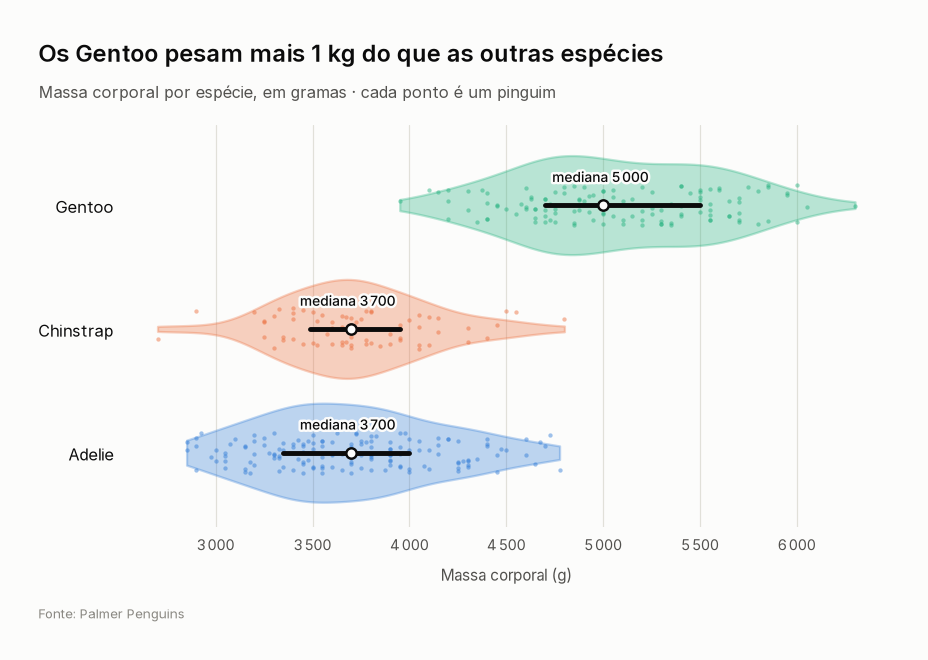

In [64]:
fig, ax = caixa(
    pinguins, coluna="massa_g", por="especie",
    titulo="Os Gentoo pesam mais 1 kg do que as outras espécies",
    subtitulo="Massa corporal por espécie, em gramas · cada ponto é um pinguim",
    rotulo="Massa corporal (g)", fonte="Palmer Penguins",
)

E as duas "montanhas" do histograma da secção 6.3? Com `cor_por="especie"`, cada espécie tem o seu histograma, por cima dos outros:

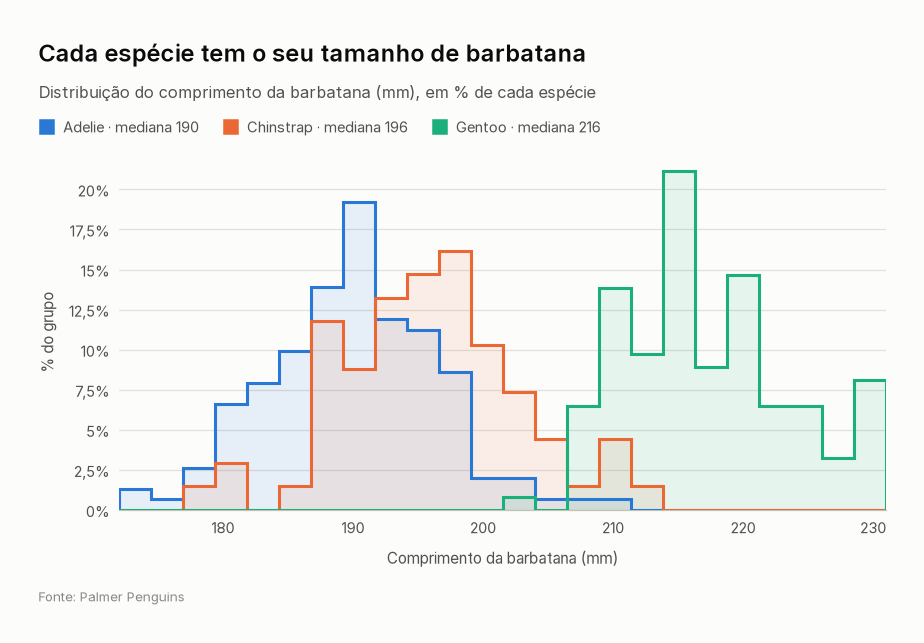

In [65]:
fig, ax = histograma(
    pinguins, coluna="barbatana_mm", cor_por="especie", bins=24,
    titulo="Cada espécie tem o seu tamanho de barbatana",
    subtitulo="Distribuição do comprimento da barbatana (mm), em % de cada espécie",
    rotulo_x="Comprimento da barbatana (mm)", fonte="Palmer Penguins",
)

Por fim, o mapa de calor das correlações — com nomes curtos para as colunas e só metade da tabela (a outra metade é igual, em espelho):

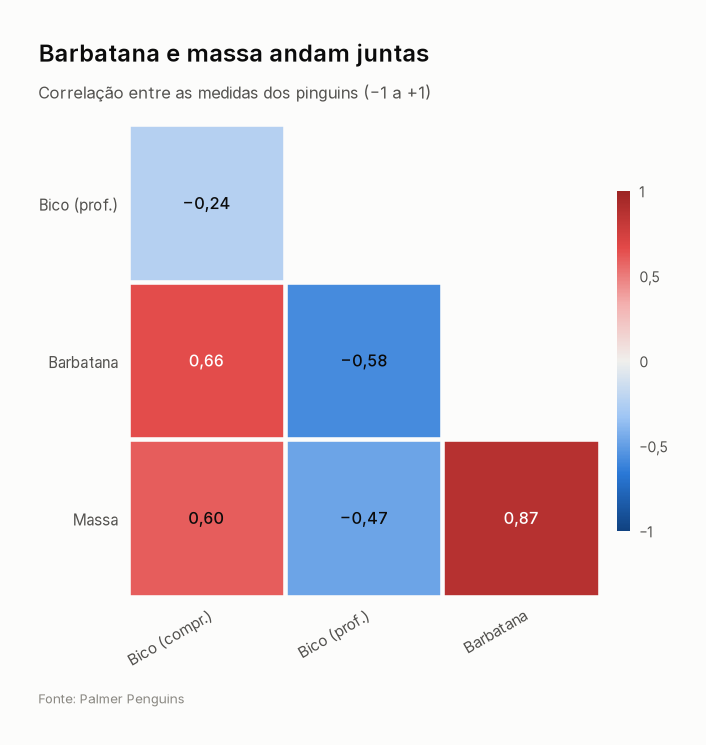

In [66]:
fig, ax = mapa_calor(
    pinguins,
    titulo="Barbatana e massa andam juntas",
    subtitulo="Correlação entre as medidas dos pinguins (−1 a +1)",
    nomes={"bico_comprimento_mm": "Bico (compr.)", "bico_profundidade_mm": "Bico (prof.)",
           "barbatana_mm": "Barbatana", "massa_g": "Massa"},
    fonte="Palmer Penguins",
)

<a id="sec-8-4"></a>

## 8.4. Galeria: o Titanic

A frase "mulheres e crianças primeiro" é verdade? Calculamos a taxa de sobrevivência por **classe e sexo** e destacamos os dois extremos:

In [67]:
taxa = titanic.groupby(["classe", "sexo"])["sobreviveu"].mean()
taxa.index = [f"{classe} · {sexo}" for classe, sexo in taxa.index]   # "1.ª classe · mulher"
print(taxa.round(2))

1.ª classe · homem     0.37
1.ª classe · mulher    0.97
2.ª classe · homem     0.16
2.ª classe · mulher    0.92
3.ª classe · homem     0.14
3.ª classe · mulher    0.50
Name: sobreviveu, dtype: float64


Gráfico guardado em output/titanic_sobrevivencia.png


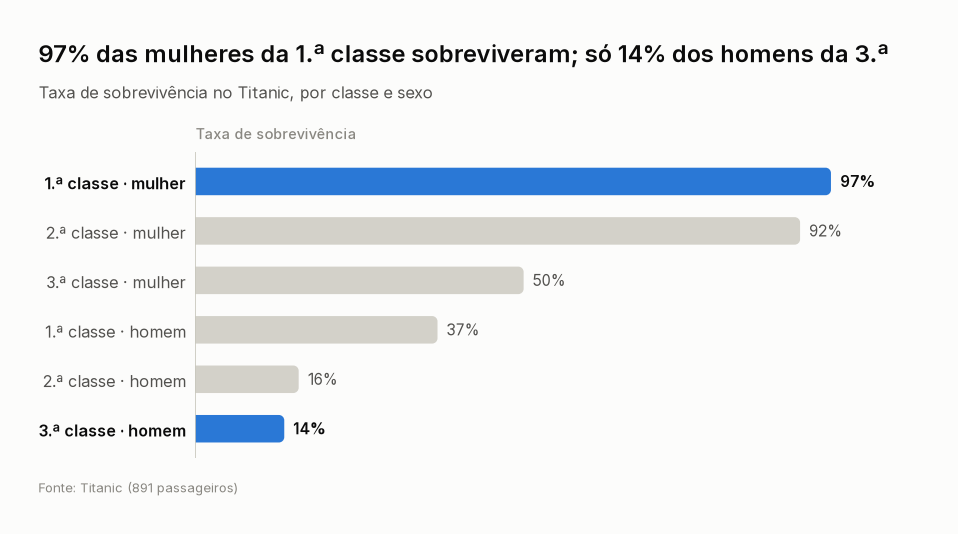

In [68]:
fig, ax = barras(
    taxa, formato="{:.0%}",
    destaque=["1.ª classe · mulher", "3.ª classe · homem"],
    titulo="97% das mulheres da 1.ª classe sobreviveram; só 14% dos homens da 3.ª",
    subtitulo="Taxa de sobrevivência no Titanic, por classe e sexo",
    rotulo_valor="Taxa de sobrevivência", fonte="Titanic (891 passageiros)",
)
guardar(fig, "titanic_sobrevivencia")

E as crianças? Comparamos as **idades** de quem sobreviveu e de quem não sobreviveu. Como os grupos têm tamanhos diferentes (342 e 549 pessoas), o eixo mostra a **percentagem de cada grupo** — assim a comparação é justa:

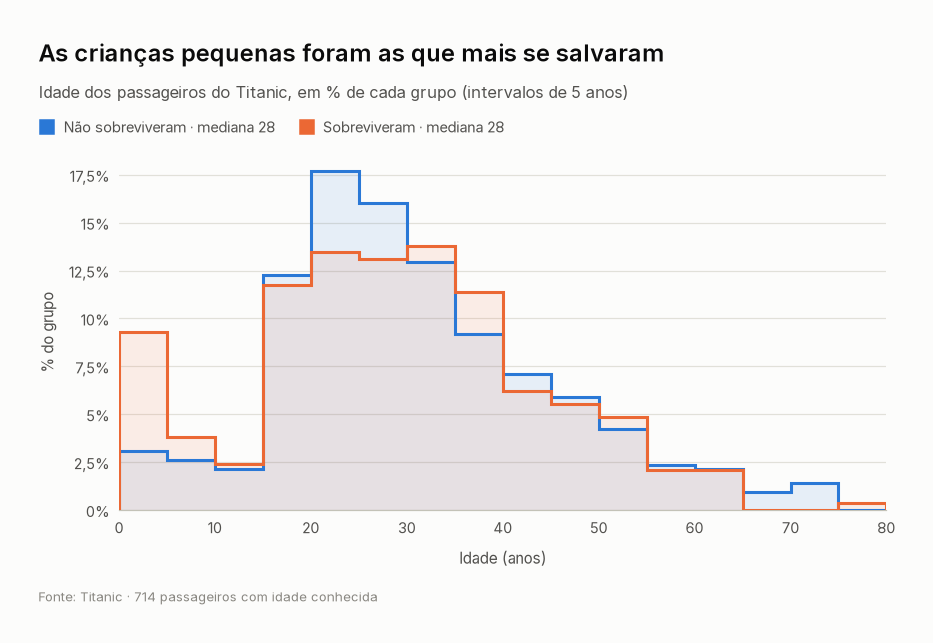

In [69]:
titanic["destino"] = titanic["sobreviveu"].map({1: "Sobreviveram", 0: "Não sobreviveram"})

fig, ax = histograma(
    titanic, coluna="idade", cor_por="destino", bins=range(0, 85, 5),
    titulo="As crianças pequenas foram as que mais se salvaram",
    subtitulo="Idade dos passageiros do Titanic, em % de cada grupo (intervalos de 5 anos)",
    rotulo_x="Idade (anos)", fonte="Titanic · 714 passageiros com idade conhecida",
)

A barra laranja dos 0–5 anos é três vezes mais alta do que a azul: entre os sobreviventes havia muito mais crianças pequenas. (As medianas são iguais, 28 anos — prova de que um só número não conta a história toda.)

Por fim, um **donut** para as partes de um todo — quantos passageiros viajavam em cada classe:

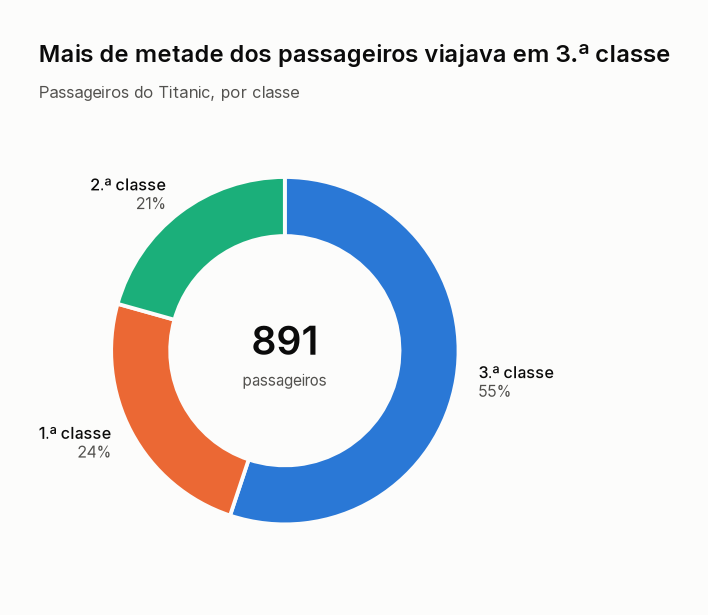

In [70]:
fig, ax = donut(
    titanic["classe"].value_counts(), legenda_centro="passageiros",
    titulo="Mais de metade dos passageiros viajava em 3.ª classe",
    subtitulo="Passageiros do Titanic, por classe",
)

<a id="sec-8-5"></a>

## 8.5. Galeria: o Dom Casmurro

Agora um romance inteiro: *Dom Casmurro*, de Machado de Assis, com mais de 65 mil palavras. Primeiro preparamos o texto.

**Cabeçalho e rodapé.** Os livros do Project Gutenberg trazem normalmente um cabeçalho e um rodapé em inglês (licença, créditos) que não fazem parte da obra. A função abaixo procura um **marcador de início** (o título do 1.º capítulo, `"Do titulo."`) e um **marcador de fim** (`"FIM"`) e fica só com o que está entre os dois. Se não os encontrar, mantém o texto todo.

In [71]:
with open("data/dom_casmurro.txt", encoding="utf-8") as f:
    linhas_dc = f.readlines()

def extrair_corpo(linhas, inicio="Do titulo.", fim="FIM"):
    # Devolve as linhas entre o marcador de início e o de fim (ou todas, se não existirem)
    i_inicio, i_fim = 0, len(linhas)
    for i, linha in enumerate(linhas):
        if linha.strip() == inicio:
            i_inicio = i + 1
            break
    for i, linha in enumerate(linhas):
        if linha.strip() == fim:
            i_fim = i
            break
    print(f"Início encontrado? {i_inicio > 0} · Fim encontrado? {i_fim < len(linhas)}")
    return linhas[i_inicio:i_fim]

corpo = extrair_corpo(linhas_dc)
print("Linhas:", len(linhas_dc), "→", len(corpo))
print("Primeira linha:", corpo[0].strip())
print("Última linha:  ", corpo[-1].strip())

Início encontrado? False · Fim encontrado? False
Linhas: 6364 → 6364
Primeira linha: Uma noite destas, vindo da cidade para o Engenho Novo, encontrei no
Última linha:   leve! Vamos á _Historia dos suburbios._


> 📝 **Nota:** os marcadores **não** foram encontrados — esta cópia do livro já vem limpa (começa logo em "Uma noite destas..." e acaba na última frase da obra). A função não estraga nada nesse caso, e continua útil se descarregares o ficheiro original do Gutenberg. Comparamos com `linha.strip() == marcador` (igualdade) e não com `marcador in linha`, para não cortarmos por engano numa linha que apenas **contém** a palavra.

**Números dos capítulos.** O texto tem 147 linhas só com o número romano do capítulo (`II.`, `III`, `XLV`...). Retiramo-las para não as contarmos como palavras:

In [72]:
def e_numero_romano(linha):
    limpa = linha.strip().rstrip(".")
    return limpa != "" and all(letra in "IVXLC" for letra in limpa)

linhas_texto = [linha.strip() for linha in corpo if not e_numero_romano(linha)]
print("Capítulos retirados:", len(corpo) - len(linhas_texto))

texto_dc = " ".join(linhas_texto)             # o livro inteiro numa só string
palavras_dc = limpar_palavras(texto_dc)        # normalizadas (secção 3.2)
print("Palavras no livro:", len(palavras_dc))
print("Palavras diferentes:", len(set(palavras_dc)))

Capítulos retirados: 147
Palavras no livro: 65019
Palavras diferentes: 9301


**Stop words de 1899.** O livro usa a ortografia da época (`elle`, `ella`, `tambem`, `ha`...), que a nossa lista não conhece. Juntamos essas formas antigas e contamos as palavras úteis:

In [73]:
STOP_WORDS_DC = STOP_WORDS | {
    "elle", "ella", "elles", "ellas", "della", "delle", "tambem", "ha", "á", "ás",
    "aquella", "aquelle", "aquillo", "tão", "lá", "cá", "onde", "assim", "então",
    "porque", "aqui", "antes", "logo", "mesmo", "outra", "outro", "outros", "outras",
    "tinha", "eram", "estava", "ia", "fosse", "bem", "vez", "nada", "ir", "sim", "pois",
}
uteis_dc = [p for p in palavras_dc if p not in STOP_WORDS_DC]
contagem_dc = Counter(uteis_dc)
print(len(STOP_WORDS_DC), "stop words ·", len(uteis_dc), "palavras úteis")
contagem_dc.most_common(5)

122 stop words · 33242 palavras úteis


[('capitú', 341), ('mãe', 228), ('dias', 191), ('casa', 170), ('olhos', 164)]

As 15 palavras mais frequentes, com a personagem principal em destaque:

Gráfico guardado em output/dom_casmurro_palavras.png


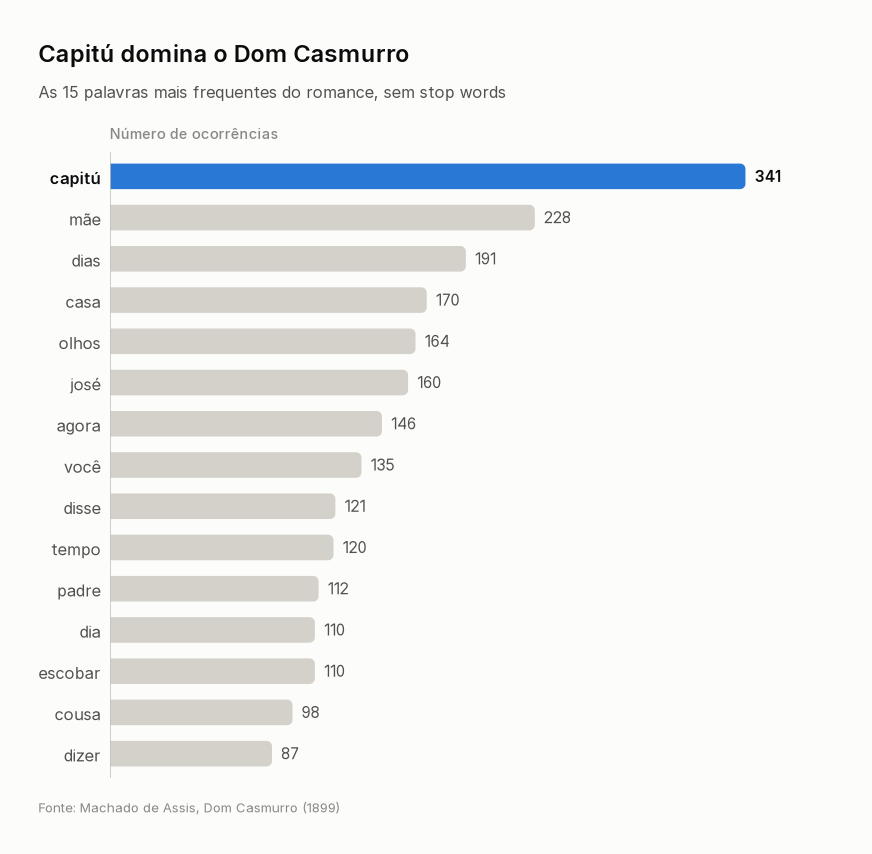

In [74]:
fig, ax = barras(
    contagem_dc.most_common(15), destaque="capitú",
    titulo="Capitú domina o Dom Casmurro",
    subtitulo="As 15 palavras mais frequentes do romance, sem stop words",
    rotulo_valor="Número de ocorrências", fonte="Machado de Assis, Dom Casmurro (1899)",
)
guardar(fig, "dom_casmurro_palavras")

E a mesma informação como nuvem de palavras — mais impressão, menos rigor. O tamanho e o tom de azul mostram a frequência; `destaque` pinta palavras a laranja:

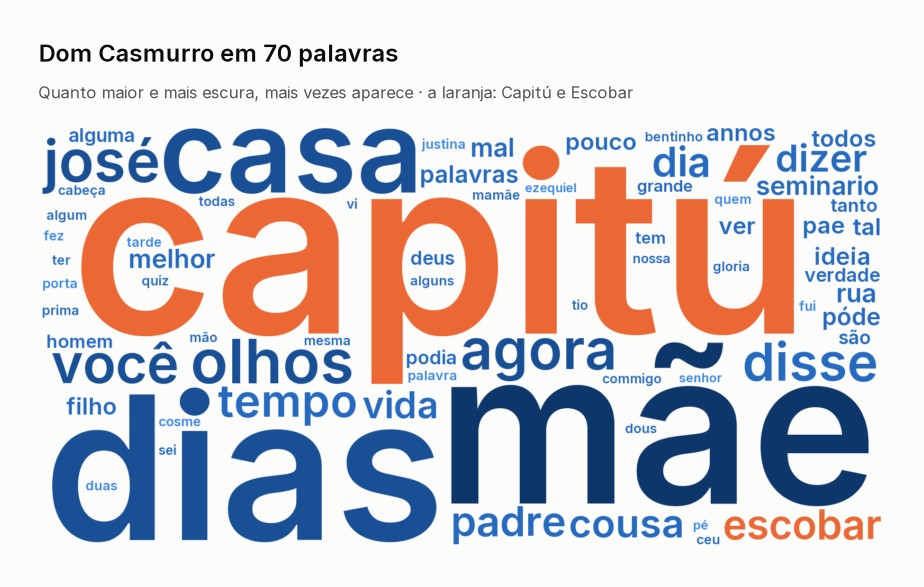

In [75]:
fig, ax = nuvem_palavras(
    contagem_dc, destaque=["capitú", "escobar"], maximo=70,
    titulo="Dom Casmurro em 70 palavras",
    subtitulo="Quanto maior e mais escura, mais vezes aparece · a laranja: Capitú e Escobar",
)

<a id="sec-8-6"></a>

## 8.6. Guardar e mudar de tema

`guardar(fig, "nome")` grava o gráfico em `output/nome.png`, com resolução alta (200 dpi), pronto para slides ou relatórios. Já o usaste três vezes nesta secção:

In [76]:
from pathlib import Path

for ficheiro in sorted(Path("output").glob("*.png")):
    print(ficheiro.name)

antes_depois.png
dom_casmurro_palavras.png
nuvem_dom_casmurro.png
pinguins_bico.png
pinguins_ilhas.png
titanic_idades.png
titanic_sobrevivencia.png


Vais apresentar num ecrã com fundo escuro? `aplicar_tema(escuro=True)` troca o fundo e ajusta as cores (as mesmas cores, num tom pensado para fundo escuro):

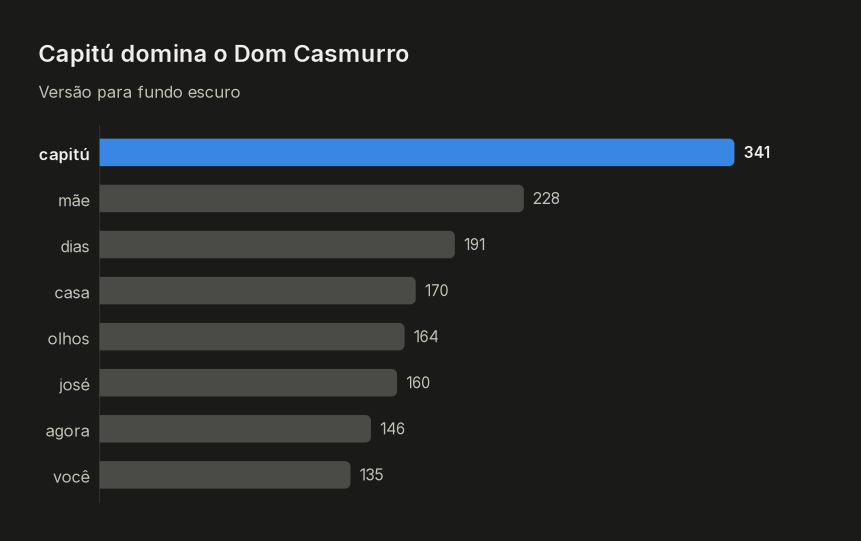

In [77]:
aplicar_tema(escuro=True)
fig, ax = barras(
    contagem_dc.most_common(8), destaque="capitú",
    titulo="Capitú domina o Dom Casmurro", subtitulo="Versão para fundo escuro",
)
aplicar_tema()   # voltamos ao tema claro para o resto do notebook

<a id="sec-8-7"></a>

## 8.7. Exercícios com o módulo

### ✏️ Exercício 6 — O teu primeiro gráfico profissional

**Dificuldade:** ⭐

Quantos pinguins foram medidos em cada **ilha**? Conta-os com `value_counts()` e desenha-os com a função `barras`, com um título que diga a conclusão, um subtítulo e a ilha com mais pinguins em `destaque`. Guarda o gráfico como `output/pinguins_ilhas.png`.

```text
ilha
Biscoe       168
Dream        124
Torgersen     52
```

In [78]:
# escreve aqui o teu código
contagem_ilhas = pd.Series(dtype=int)
print(contagem_ilhas)  # esperado: Biscoe 168, Dream 124, Torgersen 52

Series([], dtype: int64)


<details>
<summary>💡 Ver solução</summary>

```python
contagem_ilhas = pinguins["ilha"].value_counts()
print(contagem_ilhas)

fig, ax = barras(contagem_ilhas, destaque="Biscoe",
                 titulo="Metade dos pinguins vive em Biscoe",
                 subtitulo="Número de pinguins medidos em cada ilha",
                 rotulo_valor="Número de pinguins", fonte="Palmer Penguins")
guardar(fig, "pinguins_ilhas")
```

`value_counts()` devolve uma Series (ilha → contagem), que é exatamente o que `barras` aceita. O `destaque` tem de ser escrito tal e qual aparece nos dados (`"Biscoe"`). `guardar` acrescenta o `.png` e grava em `output/`.
</details>

### ✏️ Exercício 7 — Titanic: a idade em cada classe

**Dificuldade:** ⭐⭐

Usa a função `caixa` para comparar a **idade** dos passageiros nas três classes. Experimenta `tipo="caixa"` (caixa de bigodes) e depois `tipo="violino"`. Que classe tinha os passageiros mais velhos?

Calcula também as medianas com pandas para confirmar o que o gráfico mostra.

```text
classe
1.ª classe    37.0
2.ª classe    29.0
3.ª classe    24.0
```

In [79]:
# escreve aqui o teu código
medianas = pd.Series(dtype=float)
print(medianas)  # esperado: 1.ª classe 37.0 · 2.ª classe 29.0 · 3.ª classe 24.0

Series([], dtype: float64)


<details>
<summary>💡 Ver solução</summary>

```python
medianas = titanic.groupby("classe")["idade"].median()
print(medianas)

fig, ax = caixa(titanic, coluna="idade", por="classe", tipo="caixa",
                titulo="Na 1.ª classe viajavam os passageiros mais velhos",
                subtitulo="Idade dos passageiros do Titanic, por classe",
                rotulo="Idade (anos)", formato="{:.0f}", fonte="Titanic")
```

`caixa` ordena os grupos pela mediana (a maior em cima) e escreve-a no gráfico, por isso a resposta salta à vista: a 1.ª classe (mediana 37 anos). O `formato="{:.0f}"` escreve as medianas sem casas decimais. Com `tipo="violino"` vês também a **forma** das idades: a 3.ª classe tinha muitos jovens adultos.
</details>

### ✏️ Exercício 8 — Acrescenta uma função ao `graficos.py`

**Dificuldade:** ⭐⭐⭐

A função `barras` ordena sempre as barras pelo valor. Mas há categorias com uma **ordem natural** (faixas etárias, meses, anos) que não devem ser reordenadas — e que ficam melhor em **colunas verticais**.

Escreve uma função `colunas(dados, titulo, subtitulo=None, formato="{:.0%}")` que:

1. cria uma figura com `fig, ax = plt.subplots(figsize=(8, 4))`;
2. desenha colunas verticais com `ax.bar(...)`, **pela ordem original**, na cor `PALETA[0]`;
3. escreve o valor por cima de cada coluna com `ax.bar_label(...)` e esconde o eixo y (`ax.set_yticks([])`);
4. faz o acabamento com a função `moldura(fig, ax, titulo, subtitulo)` do módulo (é a que põe o título e o subtítulo em todos os outros gráficos);
5. devolve `fig, ax`.

Testa-a com a taxa de sobrevivência por faixa etária. Quando funcionar, **copia a função para o fim do `graficos.py`** e recarrega o módulo (secção 8.1) — passas a poder fazer `from graficos import colunas` em qualquer notebook desta pasta!

In [80]:
from graficos import moldura

def colunas(dados, titulo, subtitulo=None, formato="{:.0%}"):
    # escreve aqui o teu código (segue os 5 passos do enunciado)
    pass

titanic["faixa_etaria"] = pd.cut(titanic["idade"], bins=[0, 12, 18, 40, 60, 80],
                                 labels=["0–12", "13–18", "19–40", "41–60", "61–80"])
taxa_idade = titanic.groupby("faixa_etaria", observed=True)["sobreviveu"].mean()
print(taxa_idade.round(2))   # esperado: 0.58, 0.43, 0.39, 0.39, 0.23

resultado = colunas(taxa_idade, titulo="As crianças foram as que mais se salvaram")

faixa_etaria
0–12     0.58
13–18    0.43
19–40    0.39
41–60    0.39
61–80    0.23
Name: sobreviveu, dtype: float64


<details>
<summary>💡 Ver solução</summary>

```python
from graficos import moldura

def colunas(dados, titulo, subtitulo=None, formato="{:.0%}"):
    serie = pd.Series(dados)
    fig, ax = plt.subplots(figsize=(8, 4))
    retangulos = ax.bar(serie.index.astype(str), serie.values, color=PALETA[0], width=0.6)
    ax.bar_label(retangulos, labels=[formato.format(v) for v in serie.values], padding=4)
    ax.set_yticks([])                    # os valores já estão escritos por cima
    moldura(fig, ax, titulo, subtitulo)
    return fig, ax

titanic["faixa_etaria"] = pd.cut(titanic["idade"], bins=[0, 12, 18, 40, 60, 80],
                                 labels=["0–12", "13–18", "19–40", "41–60", "61–80"])
taxa_idade = titanic.groupby("faixa_etaria", observed=True)["sobreviveu"].mean()
print(taxa_idade.round(2))

fig, ax = colunas(taxa_idade, titulo="As crianças foram as que mais se salvaram",
                  subtitulo="Taxa de sobrevivência no Titanic, por faixa etária (anos)")
ax.set_xlabel("Faixa etária (anos)")
guardar(fig, "titanic_idades")
```

`pd.Series(dados)` aceita um dicionário ou uma Series; como **não** ordenamos, as faixas ficam pela ordem natural. `ax.bar_label` com `labels=` escreve o texto formatado (`0.58` → `58%`). O tema do módulo (`aplicar_tema()`) já trata das cores, do tipo de letra e da grelha, e a `moldura` acrescenta título e subtítulo alinhados — é assim que o teu gráfico fica com o mesmo aspeto dos outros. Para o juntares ao módulo, cola a função no fim do `graficos.py` (lá dentro já existem `plt`, `pd`, `PALETA` e `moldura`), guarda o ficheiro e faz `importlib.reload(graficos)`.
</details>

> 📚 **Saber mais:** [W3Schools — Módulos](https://www.w3schools.com/python/python_modules.asp) · [W3Schools — Docstrings e funções](https://www.w3schools.com/python/python_functions.asp) · [Matplotlib — galeria de exemplos](https://matplotlib.org/stable/gallery/index.html)

<a id="sec-9"></a>

# 9. Exercícios finais

Hora de juntar tudo: ficheiros, limpeza de texto, contagens, pandas e gráficos — à mão ou com o teu módulo `graficos.py`.

<a id="sec-9-1"></a>

## 9.1. Desafio: boxplot do comprimento das palavras

### ✏️ Exercício 9 — Distribuição do comprimento das palavras

**Dificuldade:** ⭐⭐

Faz uma análise descritiva da estrutura do `text.txt`: desenha um **boxplot** com o número de caracteres de cada palavra (usa a lista `palavras`, já normalizada).

O gráfico deve deixar ver:

- a **mediana** — o comprimento típico de uma palavra;
- a **dispersão** — quão variados são os comprimentos;
- os **outliers** — palavras invulgarmente compridas.

Mostra também a mediana com `print` e as palavras mais compridas.

In [81]:
# escreve aqui o teu código
comprimentos = []
print("Mediana:", pd.Series(comprimentos, dtype=float).median())  # esperado: 5.0

Mediana: nan


<details>
<summary>💡 Ver solução</summary>

```python
comprimentos = [len(p) for p in palavras]
print("Mediana:", pd.Series(comprimentos, dtype=float).median())
print("Mais compridas:", sorted(set(palavras), key=len, reverse=True)[:3])

plt.figure(figsize=(9, 2.8))
sns.boxplot(x=comprimentos, color=AZUL, width=0.45, boxprops={"alpha": 0.35})
plt.title("Metade das palavras do texto tem até 5 letras", weight="bold", loc="left")
plt.xlabel("Número de caracteres da palavra")
plt.tight_layout()
plt.show()
```

Uma compreensão de lista transforma cada palavra no seu comprimento; o `boxplot` faz o resto. Metade das palavras tem até 5 letras, e as mais compridas (`desenvolvimento`, `arquitetura`, `colaboração`) aparecem à direita.
</details>

<a id="sec-9-2"></a>

## 9.2. Desafio: analisar o Dom Casmurro

O texto já foi preparado na [secção 8.5](#sec-8-5). Vais usar:

- `texto_dc` — o livro inteiro numa string;
- `palavras_dc` — a lista de palavras normalizadas;
- `contagem_dc` — um `Counter` das palavras úteis (sem `STOP_WORDS_DC`).

### ✏️ Exercício 10 — Dom Casmurro (a): quem é mais mencionado?

**Dificuldade:** ⭐⭐

Conta quantas vezes aparece o nome de cada personagem da lista `PERSONAGENS` (usa `contagem_dc`) e desenha o resultado com a função `barras`, com o narrador, `"bentinho"`, em destaque.

Repara no lugar do Bentinho: porque achas que o narrador quase não diz o próprio nome?

*Dica:* uma compreensão de dicionário: `{nome: contagem_dc[nome] for nome in PERSONAGENS}`.

In [82]:
PERSONAGENS = ["capitú", "josé", "escobar", "gloria", "bentinho", "justina", "cosme", "ezequiel", "sancha"]
# escreve aqui o teu código
mencoes = {}
print(mencoes)  # esperado: {'capitú': 341, 'josé': 160, 'escobar': 110, ...}

{}


<details>
<summary>💡 Ver solução</summary>

```python
PERSONAGENS = ["capitú", "josé", "escobar", "gloria", "bentinho", "justina", "cosme", "ezequiel", "sancha"]
mencoes = {nome: contagem_dc[nome] for nome in PERSONAGENS}
print(mencoes)

fig, ax = barras(mencoes, destaque="bentinho",
                 titulo="O narrador quase não diz o próprio nome",
                 subtitulo="Menções a cada personagem em Dom Casmurro",
                 rotulo_valor="Número de menções", fonte="Machado de Assis, Dom Casmurro (1899)")
```

A compreensão de dicionário cria o par `nome → contagem` para cada personagem (um `Counter` devolve 0 para palavras que não conhece, em vez de dar erro). Bentinho conta a história na 1.ª pessoa — diz "eu", não "Bentinho" — por isso o seu nome aparece menos do que o de Capitú, José Dias ("josé") ou Escobar.
</details>

### ✏️ Exercício 11 — Dom Casmurro (b): comprimento das frases ao longo do livro

**Dificuldade:** ⭐⭐⭐

Divide `texto_dc` em **frases** e calcula quantas palavras tem cada uma. Desenha um gráfico de linhas com o comprimento das frases ao longo do livro e, por cima, uma **média móvel** de 100 frases, que mostra a tendência.

*Dicas:*
- troca `"!"` e `"?"` por `"."` e depois usa `.split(".")`;
- ignora "frases" vazias (com 0 palavras);
- põe os comprimentos numa `pd.Series` e usa a função `linha` do módulo com `media_movel=100`.

In [83]:
# escreve aqui o teu código
comprimentos_frases = []
print("Frases:", len(comprimentos_frases))  # esperado: 4555

Frases: 0


<details>
<summary>💡 Ver solução</summary>

```python
texto_frases = texto_dc.replace("!", ".").replace("?", ".")
comprimentos_frases = [len(f.split()) for f in texto_frases.split(".") if f.split()]
print("Frases:", len(comprimentos_frases))

serie = pd.Series(comprimentos_frases)
print("Média de palavras por frase:", round(serie.mean(), 1))

fig, ax = linha(serie, media_movel=100,
                titulo="O ritmo das frases é estável do início ao fim",
                subtitulo="Palavras por frase ao longo do Dom Casmurro",
                rotulo_x="Número da frase", rotulo_y="Palavras na frase")
```

Normalizamos os finais de frase para `"."` e partimos o texto; `if f.split()` descarta pedaços vazios (por exemplo, das reticências). A linha cinzenta é muito irregular, mas a média móvel mostra que o ritmo das frases é bastante estável ao longo do livro. (A divisão não é perfeita — abreviaturas como `cap.` também cortam — mas chega para ver a tendência.) Sem o módulo, farias o mesmo com `plt.plot(serie)` e `plt.plot(serie.rolling(100).mean())`.
</details>

### ✏️ Exercício 12 — Dom Casmurro (c): distribuição do comprimento das palavras

**Dificuldade:** ⭐⭐

Cria um DataFrame com uma coluna `comprimento` (número de letras de cada palavra de `palavras_dc`) e desenha, lado a lado, um **histograma** (`sns.histplot` com `discrete=True`) e um **boxplot** dessa coluna.

Qual é o comprimento mais comum (a moda)? E a mediana?

In [84]:
# escreve aqui o teu código
df_comp = pd.DataFrame({"comprimento": []})
print(df_comp["comprimento"].describe())  # esperado: count 65019, mediana (50%) = 4

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: comprimento, dtype: float64


<details>
<summary>💡 Ver solução</summary>

```python
df_comp = pd.DataFrame({"comprimento": [len(p) for p in palavras_dc]})
print(df_comp["comprimento"].describe())
print("Mais comum:", df_comp["comprimento"].mode()[0])

fig, (esq, dir) = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df_comp, x="comprimento", discrete=True, ax=esq, color=AZUL, edgecolor="white")
esq.set_title("O comprimento mais comum é 3 letras", weight="bold", loc="left")
esq.set_xlabel("Letras")
esq.set_ylabel("Número de palavras")
sns.boxplot(data=df_comp, x="comprimento", ax=dir, color=AZUL, width=0.45, boxprops={"alpha": 0.35})
dir.set_title("Metade das palavras tem até 4 letras", weight="bold", loc="left")
dir.set_xlabel("Letras")
plt.tight_layout()
plt.show()
```

`discrete=True` faz uma barra por cada comprimento inteiro. O comprimento mais comum é 3 letras e a mediana é 4. Com `plt.subplots(1, 2)` criamos dois eixos e indicamos a cada gráfico onde desenhar com `ax=`. As palavras curtas (artigos, preposições) dominam; as mais compridas são outliers no boxplot.
</details>

### ✏️ Exercício 13 — Dom Casmurro (d): distribuição das vogais

**Dificuldade:** ⭐⭐

Conta as vogais de `texto_dc`, **incluindo as acentuadas**: `á`, `à`, `â`, `ã` contam como `a`; `é`, `ê` como `e`; e assim por diante. Mostra o resultado com a função `donut` do módulo.

*Dica:* cria um dicionário que diz a que vogal pertence cada letra, por exemplo `{"a": "a", "á": "a", "ã": "a", ...}`.

In [85]:
# escreve aqui o teu código
vogais_dc = {"a": 0, "e": 0, "i": 0, "o": 0, "u": 0}
print(vogais_dc)  # esperado: o 'a' é a vogal mais frequente

{'a': 0, 'e': 0, 'i': 0, 'o': 0, 'u': 0}


<details>
<summary>💡 Ver solução</summary>

```python
grupos = {"a": "aáàâã", "e": "eéê", "i": "ií", "o": "oóôõ", "u": "uúü"}
vogal_de = {}
for vogal, letras in grupos.items():
    for letra in letras:
        vogal_de[letra] = vogal          # ex.: vogal_de["ã"] = "a"

vogais_dc = {"a": 0, "e": 0, "i": 0, "o": 0, "u": 0}
for letra in texto_dc.lower():
    if letra in vogal_de:
        vogais_dc[vogal_de[letra]] += 1
print(vogais_dc)

fig, ax = donut(vogais_dc, legenda_centro="vogais",
                titulo="O «a» é a vogal mais usada no Dom Casmurro",
                subtitulo="Vogais do romance, com e sem acento")
```

O dicionário `vogal_de` traduz cada letra (com ou sem acento) para a sua vogal base; assim basta um `if letra in vogal_de` dentro do ciclo. A função `donut` ordena as fatias da maior para a menor e escreve o total no centro.
</details>

### ✏️ Exercício 14 — Dom Casmurro (e): nuvem de palavras à mão

**Dificuldade:** ⭐

Gera uma **WordCloud** do Dom Casmurro **sem** as stop words (`STOP_WORDS_DC`), diretamente com a biblioteca `wordcloud` (como na secção 5.6). Usa um fundo branco e a paleta `"viridis"`, e guarda a imagem em `output/nuvem_dom_casmurro.png`.

*Dica:* depois de gerada, uma nuvem guarda-se com `nuvem.to_file("caminho.png")`.

In [86]:
# escreve aqui o teu código
# nuvem_dc = WordCloud(...).generate(" ".join(palavras_dc))
print("Nuvem por fazer")  # esperado: uma nuvem com 'capitú' em destaque

Nuvem por fazer


<details>
<summary>💡 Ver solução</summary>

```python
nuvem_dc = WordCloud(
    width=1200, height=600, background_color="white", colormap="viridis",
    stopwords=STOP_WORDS_DC, collocations=False, random_state=42,
).generate(" ".join(palavras_dc))
nuvem_dc.to_file("output/nuvem_dom_casmurro.png")

plt.figure(figsize=(12, 6))
plt.imshow(nuvem_dc, interpolation="bilinear")
plt.axis("off")
plt.title("Dom Casmurro em palavras", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()
```

É a receita da secção 5.6, agora com as stop words do livro. Compara com a `nuvem_palavras` da secção 8.5: o módulo escolhe as cores pela frequência e permite destacar palavras; a biblioteca dá-te controlo total sobre cada parâmetro.
</details>

> 📚 **Saber mais:** [Seaborn — galeria de exemplos](https://seaborn.pydata.org/examples/index.html) · [W3Schools — Histogramas](https://www.w3schools.com/python/matplotlib_histograms.asp)

<a id="praticar-mais"></a>

## 🏋️ Praticar mais

- [W3Schools — Python Exercises](https://www.w3schools.com/python/python_exercises.asp): exercícios curtos e interativos sobre tudo o que viste nesta lição.
- [Matplotlib — galeria de exemplos](https://matplotlib.org/stable/gallery/index.html): centenas de gráficos com o código ao lado — escolhe um e adapta-o aos teus dados.
- **Desafio livre:** acrescenta ao `graficos.py` uma função para um gráfico que ainda não tem (por exemplo, barras empilhadas ou pequenos múltiplos com `plt.subplots`) e usa a `moldura` para lhe dar o mesmo acabamento.

<a id="sec-10"></a>

# 📌 Resumo

| Conceito | Sintaxe | Exemplo |
|---|---|---|
| Sequências de escape | `\n`, `\t`, `\\`, `\"` | `print("a\tb\nc")` |
| Raw string | `r"..."` | `r"C:\pasta\f.txt"` |
| Ler ficheiro | `with open(caminho, encoding="utf-8") as f:` | `texto = f.read()` |
| Escrever / acrescentar | modo `"w"` (apaga!) / `"a"` | `f.write("linha\n")` |
| Remover uma linha | ler → filtrar → reescrever | `[l for l in linhas if ...]` |
| Copiar ficheiro | `shutil.copy(origem, destino)` | `shutil.copy("data/t.txt", "output/t.txt")` |
| Normalizar palavras | `.lower()` + `.strip(pontuacao)` | `limpar_palavras(texto)` |
| Contar e Top N | `Counter(lista).most_common(n)` | `Counter(palavras).most_common(10)` |
| Stop words | filtrar com um `set` | `[p for p in palavras if p not in STOP_WORDS]` |
| Guardar gráfico | `plt.savefig(caminho, dpi=150)` | antes de `plt.show()` |
| Importar do teu ficheiro | `from módulo import nome` | `from graficos import barras` |
| Recarregar um módulo alterado | `importlib.reload(módulo)` | `importlib.reload(graficos)` |
| Ver a ajuda de uma função | `help(função)` | `help(barras)` |

**Matplotlib vs Seaborn vs o teu módulo**

| Gráfico | Matplotlib | Seaborn (com DataFrame) | `graficos.py` | Usa para... |
|---|---|---|---|---|
| Barras | `plt.bar(x, y)` / `plt.barh(x, y)` | `sns.barplot(data=df, x=, y=)` | `barras(dados, titulo, destaque=)` | comparar categorias |
| Linhas | `plt.plot(x, y)` | `sns.lineplot(data=df, x=, y=)` | `linha(dados, titulo, media_movel=)` | evolução numa sequência |
| Dispersão | `plt.scatter(x, y)` | `sns.scatterplot(data=df, x=, y=, hue=)` | `dispersao(df, x, y, cor=)` | relação entre 2 números |
| Histograma | `plt.hist(valores)` | `sns.histplot(data=df, x=)` | `histograma(df, coluna, cor_por=)` | distribuição |
| Boxplot / violino | `plt.boxplot(valores)` | `sns.boxplot(data=df, x=, y=)` | `caixa(df, coluna, por=, tipo=)` | distribuição por grupo, outliers |
| Circular | `plt.pie(valores, labels=)` | — (usa Matplotlib) | `donut(dados, titulo)` | partes de um todo (poucas) |
| Mapa de calor | `plt.imshow(matriz)` | `sns.heatmap(df.corr(), annot=True)` | `mapa_calor(df, titulo)` | correlações / matrizes |
| Nuvem de palavras | — | — | `nuvem_palavras(contagem, titulo)` | primeira impressão de um texto |

> 💡 **Regra prática:** Matplotlib dá controlo total sobre cada detalhe; Seaborn dá gráficos estatísticos com uma linha, a partir de um DataFrame; e um **módulo teu** guarda as tuas escolhas de estilo para nunca mais as repetires. Como tudo usa Matplotlib por baixo, podes sempre afinar com `ax.set_title`, `ax.set_xlim`, `plt.savefig`...

---
<div align="center">

⬅️ [Anterior: 05 · Pandas](../05_Pandas/05_Pandas.ipynb) &nbsp;·&nbsp; 🏠 [Lição 01](../../README.md) &nbsp;·&nbsp; Seguinte: Lição 02 · Modelos de ML (em breve) ➡️

**The AI Learning Hub** · Lição 01 — Python: primeiros passos<br>
Diogo Freitas & João Francisco Botas · Licença MIT

</div>